# APM_50441_EP - Machine Learning 2 - Lab 6: Reinforcement learning

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/APM-50441-EP/APM_50441_EP-2026-2027/blob/main/PC6/APM_50441_EP_Lab_6_with_solution.ipynb) or run it on your own computer (see *Working environment* below).

This lab illustrates the sixth lecture (*Reinforcement Learning*) on the Cliff Walking problem of the lecture. Its goals are:
- to describe a Markov decision process and its model, and to solve it by dynamic programming (policy evaluation, value iteration, policy iteration),
- to compare Monte Carlo and temporal difference estimation of a value function,
- to implement SARSA and Q-learning, and to understand why they learn different paths,
- to implement the REINFORCE policy gradient in PyTorch, and to see the effect of the reward-to-go on its variance.

The optional *To go further* part, after the core, can be skipped at first: it covers bandits, more temporal difference methods, the deadly triad, deep RL (DQN, actor-critic, PPO) and the RL of language models (GRPO, DPO, agents).

We use `Python` with `numpy`, `gymnasium` and `PyTorch`. The environment, its tabular model and drawing helpers are in the small module `RL.py` (no algorithm in it: you write them).

**Working environment.** Colab is the simplest option: open the notebook of this lab from the course repository (*Open in Colab* link) and run it. To work on your own computer, download the lab folder (the notebook and its files) or clone the course repository, and open the notebook in an IDE that runs Jupyter notebooks (VS Code with the Python and Jupyter extensions, JupyterLab, Spyder, PyCharm). Create a Python environment once with [`uv`](https://docs.astral.sh/uv/): `uv venv`, activate it (`source .venv/bin/activate`, or `.venv\Scripts\activate` on Windows) and `uv pip install jupyter`, or build the whole course environment with `uv sync` in `PC/env`; then select this environment as the kernel of the notebook. The installation cell below installs the packages of the lab into the Python running the notebook (Colab or your environment), and the data are read from the local files when they are present (otherwise they are downloaded).

**Use of AI.** AI assistants are allowed, but you must be able to explain every line you use, and you should answer the *predict before you run* questions before running the code: the suggested code may not be correct!

In [2]:
# Installs into the Python running this notebook: Colab, or locally an activated virtual environment
import sys
!uv pip install --python "{sys.executable}" "gymnasium[toy-text]==1.2.*" "torch" "polars==1.44.2" "seaborn==0.13.2"

Using Python 3.12.14 environment at: ~\.venvs\apm50441
Checked 4 packages in 37ms


In [3]:
import os
import urllib.request
if not os.path.exists("RL.py"):
  urllib.request.urlretrieve("https://raw.githubusercontent.com/APM-50441-EP/APM_50441_EP-2026-2027/main/PC6/RL.py", "RL.py")
import time
import numpy as np
import polars as pl
import seaborn.objects as so
import matplotlib.pyplot as plt
import gymnasium as gym
import torch
torch.set_num_threads(2)
import RL
from RL import NS, NA, START, GOAL, VALID, UP, RIGHT, DOWN, LEFT

## 1. The environment

Cliff Walking (Sutton and Barto, Example 6.6, and the lecture) is a $4 \times 12$ grid: the agent starts in S (bottom left), must reach G (bottom right), and pays $-1$ per step; stepping into the cliff costs $-100$ and sends it back to S. The states are numbered $s = 12 \times \text{row} + \text{column}$ and the actions are $0$ = up, $1$ = right, $2$ = down, $3$ = left. A `gymnasium` environment is used through `reset()` and `step(action)`, which returns the next state, the reward, and whether the episode is *terminated* (goal reached) or *truncated* (time limit).

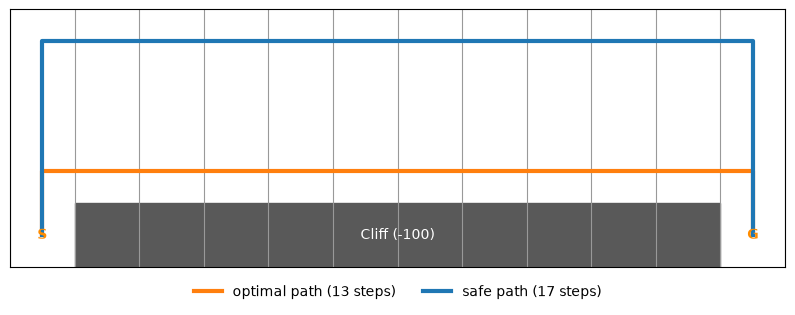

In [4]:
fig, ax = plt.subplots(figsize=(10, 3.5))
RL.draw_grid(ax, paths=[(RL.OPTIMAL_PATH, 'tab:orange', 'optimal path (13 steps)'), (RL.SAFE_PATH, 'tab:blue', 'safe path (17 steps)')])

**Question** *Predict before you run:* what is the average return of the uniformly random policy, with episodes cut after $500$ steps? Run $200$ such episodes in `RL.make_env(max_steps=500)` and report the mean return, the mean length and the proportion of episodes reaching the goal.

**Answer**

In [5]:
env = RL.make_env(max_steps=500)
env.action_space.seed(0)
episodes = []
for episode in range(200):
  s, _ = env.reset(seed=episode)
  total, length, done = 0, 0, False
  while not done:
    s, r, terminated, truncated, _ = env.step(env.action_space.sample())
    total, length, done = total + r, length + 1, terminated or truncated
  episodes.append({'return': total, 'length': length, 'goal': terminated})
pl.DataFrame(episodes).mean()

return,length,goal
f64,f64,f64
-5054.355,486.495,0.07


**Conclusion** The uniformly random policy is terrible: the mean return over $500$ steps is about $-5000$, as the agent falls into the cliff about $45$ times per episode ($-100$ each) on top of the $-1$ per step, and only $7\%$ of the episodes reach the goal within $500$ steps. Exploring at random in this environment is very costly, which is why the exploration of the learning algorithms below matters.

---

The lecture also uses a *slippery* version: with probability $10\%$, the chosen action is replaced by a uniformly random one. `RL.tabular_model(slip)` returns its model: the transition probabilities `P[s, a, s']` and the expected rewards `R[s, a]` (the goal is absorbing, with reward $0$).

**Question** Build the model with `slip=0.1`. Check that each `P[s, a]` is a probability distribution. Where can the agent go from S when it chooses *right*, with which probabilities? Compute `R[START, RIGHT]` by hand and compare.

**Answer**

In [6]:
P, R = RL.tabular_model(slip=0.1)
print('rows sum to one:', np.allclose(P.sum(axis=2), 1))
print({int(s2): round(float(p), 3) for s2, p in enumerate(P[START, RIGHT]) if p > 0})
{'R[START, RIGHT]': R[START, RIGHT], 'by hand': 0.9 * (-100) + 0.1 * (-1 - 100 - 1 - 1) / 4}

rows sum to one: True
{24: 0.025, 36: 0.975}


{'R[START, RIGHT]': np.float64(-92.57500000000002), 'by hand': -92.575}

**Conclusion** Every `P[s, a]` sums to $1$. From S, choosing *right* sends the agent to S again with probability $0.975$ (the cliff sends it back to S, and the slips *down* and *left* bump into the wall), and *up* with probability $0.025$ (a slip). The expected reward is $0.9 \times (-100) + 0.1 \times \frac{-1 - 100 - 1 - 1}{4} = -92.575$, as computed by the model: with probability $0.9 + 0.025$, the agent falls.

---

## 2. Dynamic programming

With a known model and a discount $\gamma = 0.9$, the value of a stationary policy $\pi$ solves the Bellman equation $v_\pi = r_\pi + \gamma P_\pi v_\pi$, with $P_\pi(s, s') = \sum_a \pi(a|s)P(s, a, s')$ and $r_\pi(s) = \sum_a\pi(a|s)R(s, a)$. It can be computed exactly by solving this linear system, or by iterating the Bellman operator $v \mapsto r_\pi + \gamma P_\pi v$, a $\gamma$-contraction for the sup norm (PC6). The optimal value $v_\star$ is the fixed point of the *optimal* Bellman operator $v \mapsto \max_a\big(R(\cdot, a) + \gamma P(\cdot, a)v\big)$.

**Question** For the uniform policy on the slippery grid ($\gamma = 0.9$), compute $v_\pi$ exactly with `np.linalg.solve`, then by $60$ iterations of the Bellman operator from $v = 0$. Plot the sup-norm error (over the valid states) along the iterations in log scale, with the bound $\gamma^k\|v_0 - v_\pi\|_\infty$. Display $v_\pi$ on the grid.

**Answer**

v_uniform(S) = -150.8961022437207


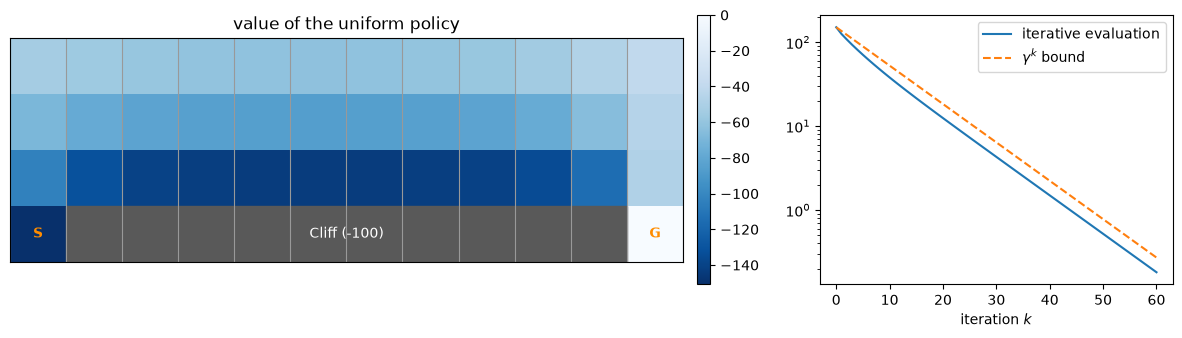

In [7]:
gamma = 0.9
uniform = np.full((NS, NA), 1 / NA)
def evaluate(pi, P=P, R=R, gamma=gamma):
  P_pi, r_pi = np.einsum('sa,sat->st', pi, P), (pi * R).sum(axis=1)
  return np.linalg.solve(np.eye(NS) - gamma * P_pi, r_pi)
v_uniform = evaluate(uniform)
P_pi, r_pi = np.einsum('sa,sat->st', uniform, P), (uniform * R).sum(axis=1)
v, errors = np.zeros(NS), []
for k in range(61):
  errors.append(np.abs(v - v_uniform)[VALID].max())
  v = r_pi + gamma * P_pi @ v
fig, axes = plt.subplots(1, 2, figsize=(15, 3.5), gridspec_kw=dict(width_ratios=[2, 1]))
RL.draw_grid(axes[0], values=v_uniform, title='value of the uniform policy')
axes[1].semilogy(errors, label='iterative evaluation')
axes[1].semilogy(errors[0] * gamma ** np.arange(61), '--', label=r'$\gamma^k$ bound')
axes[1].legend(); axes[1].set_xlabel('iteration $k$')
print('v_uniform(S) =', v_uniform[START])

**Conclusion** The value of the uniform policy from S is $-151$ (with $\gamma = 0.9$): the states next to the cliff have the lowest values, since a random move falls with probability $1/4$. The iterative evaluation converges geometrically, and its error stays below the bound $\gamma^k\|v_0 - v_\pi\|_\infty$: the Bellman operator is a $\gamma$-contraction for the sup norm (PC6), so that the number of iterations needed for a precision $\varepsilon$ is about $\log(\varepsilon)/\log(\gamma)$. The exact solution of the linear system gives the same result directly, at a cost cubic in the number of states.

---

**Question** Implement value iteration (iterate the optimal Bellman operator from $v = 0$ until the sup-norm change is below $10^{-10}$). Display $v_\star$ with the greedy policy $\arg\max_a\big(R(s, a) + \gamma P(s, a)v_\star\big)$ and its path from S (without slips). Then solve the problem without slips (`slip=0`) and compare the paths.

**Answer**

{'iterations': 63,
 'v*(S), slip 10%': np.float64(-11.353475009722432),
 'v*(S), no slip': np.float64(-7.458134171671),
 'path length, slip 10%': 15,
 'path length, no slip': 13}

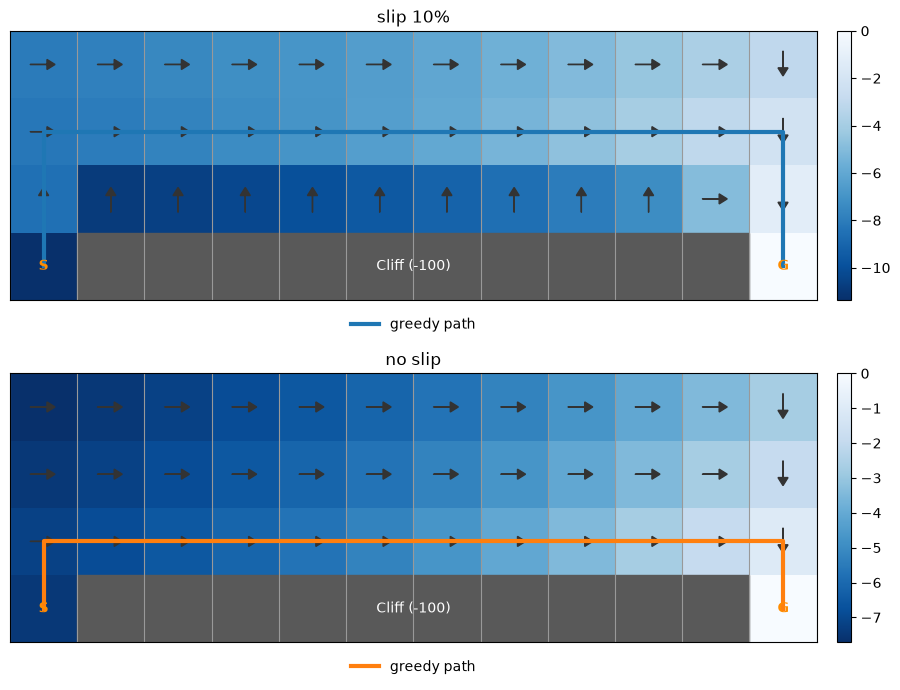

In [8]:
def value_iteration(P, R, gamma=0.9, tol=1e-10):
  v = np.zeros(NS)
  for iteration in range(10_000):
    v_new = (R + gamma * P @ v).max(axis=1)
    if np.abs(v_new - v).max() < tol:
      return v_new, iteration + 1
    v = v_new
v_star, iterations = value_iteration(P, R)
greedy = (R + gamma * P @ v_star).argmax(axis=1)
P0, R0 = RL.tabular_model(slip=0.0)
v_star0, _ = value_iteration(P0, R0)
greedy0 = (R0 + gamma * P0 @ v_star0).argmax(axis=1)
fig, axes = plt.subplots(2, 1, figsize=(11, 7))
RL.draw_grid(axes[0], values=v_star, actions=greedy, paths=[(RL.greedy_path(greedy), 'tab:blue', 'greedy path')], title='slip 10%')
RL.draw_grid(axes[1], values=v_star0, actions=greedy0, paths=[(RL.greedy_path(greedy0), 'tab:orange', 'greedy path')], title='no slip')
fig.tight_layout()
{'iterations': iterations, 'v*(S), slip 10%': v_star[START], 'v*(S), no slip': v_star0[START],
 'path length, slip 10%': len(RL.greedy_path(greedy)) - 1, 'path length, no slip': len(RL.greedy_path(greedy0)) - 1}

**Conclusion** Value iteration converges in $63$ iterations. With $10\%$ of slips, $v_\star(S) = -11.35$ and the greedy path climbs two rows away from the cliff before going right ($15$ steps): one step along the cliff risks a fall with probability $2.5\%$, at a cost of $-100$, which is not worth the $2$ steps saved. Without slips, the optimal path goes right along the cliff ($13$ steps, $v_\star(S) = -7.46$ with discount). The arrows of the greedy policy point away from the cliff everywhere near it: the optimal policy depends on the risk, not only on the shortest path.

---

**Question** Implement policy iteration: start from the policy "always right" (which walks into the cliff), evaluate it exactly, take the greedy policy, and repeat until the policy does not change. How many iterations are needed? Plot the sup-norm error $\|v_{\pi_k} - v_\star\|_\infty$ along the iterations together with the one of value iteration.

**Answer**

{'policy iteration steps': 13, 'same policy as value iteration': True}

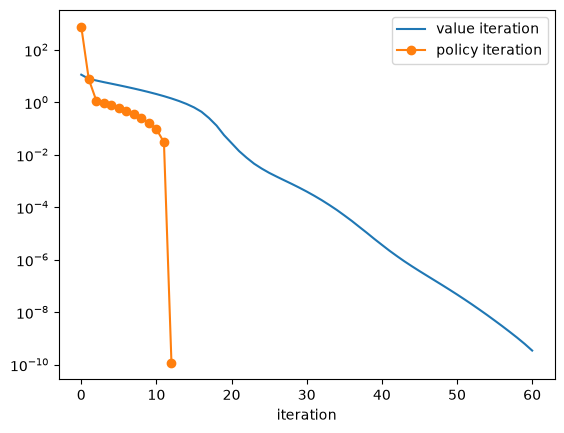

In [9]:
actions, pi_errors = np.full(NS, RIGHT), []
while True:
  v_pi = evaluate(np.eye(NA)[actions])
  pi_errors.append(np.abs(v_pi - v_star)[VALID].max())
  new_actions = (R + gamma * P @ v_pi).argmax(axis=1)
  if np.array_equal(new_actions, actions):
    break
  actions = new_actions
v, vi_errors = np.zeros(NS), []
for k in range(61):
  vi_errors.append(np.abs(v - v_star)[VALID].max())
  v = (R + gamma * P @ v).max(axis=1)
plt.semilogy(vi_errors, label='value iteration')
plt.semilogy(np.maximum(pi_errors, 1e-14), 'o-', label='policy iteration')
plt.xlabel('iteration'); plt.legend()
{'policy iteration steps': len(pi_errors), 'same policy as value iteration': bool(np.array_equal(actions[VALID], greedy[VALID]))}

**Conclusion** Policy iteration converges in $13$ iterations to the same policy as value iteration. Its error decreases much faster than the geometric rate of value iteration, and becomes exactly $0$ (up to the precision of the linear solver) when the policy stops changing: each iteration is more expensive (an exact policy evaluation) but improves the policy a lot, and there are only finitely many deterministic policies.

---

## 3. Monte Carlo and temporal difference estimation

Without a model, the value of a policy is estimated from episodes. *Monte Carlo* (MC) moves $V(s_t)$ towards the observed return $G_t$; *temporal difference* TD(0) moves it towards the *bootstrapped* target $r_{t+1} + \gamma V(s_{t+1})$, after each step. We compare them on the random walk of the lecture (Sutton and Barto, Example 6.2): $5$ states A to E, start in C, left or right with probability $1/2$, reward $1$ when leaving on the right; the true values are $1/6, \dots, 5/6$. `RL.random_walk_episode(rng)` returns the transitions $(s, r, s')$ of an episode ($s' = $ `None` at the end).

**Question** Implement every-visit MC and TD(0) with a constant step size $\alpha$ and the values initialized at $0.5$ (no discount). For $\alpha \in \{0.01, 0.02, 0.05, 0.1, 0.2, 0.3\}$, compute the RMS error over the $5$ states after each of $100$ episodes, averaged over $100$ runs. Plot the curves of the best $\alpha$ of each method, and the final error (mean over the last $10$ episodes) as a function of $\alpha$.

**Answer**

alpha,MC,TD
f64,f64,f64
0.01,0.098186,0.131978
0.02,0.080903,0.073683
0.05,0.118159,0.036579
0.1,0.167994,0.05511
0.2,0.222961,0.08237
0.3,0.27432,0.11061


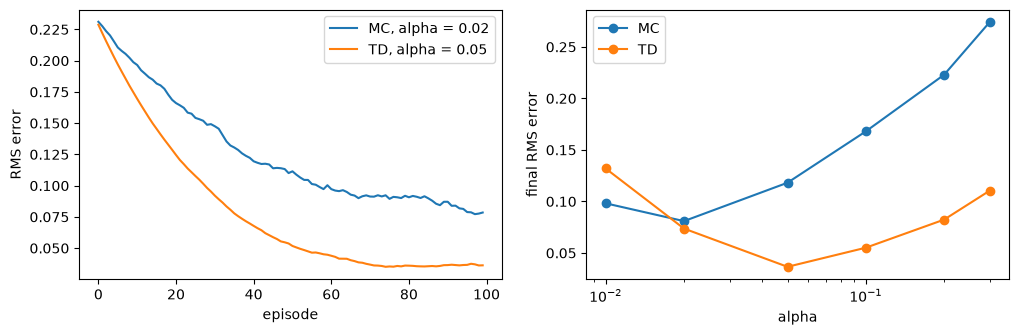

In [10]:
V_true = np.arange(1, 6) / 6
def estimate(method, alpha, n_episodes, rng, step_size=None):
  V, counts, errors = np.full(5, 0.5), np.zeros(5), np.zeros(n_episodes)
  for e in range(n_episodes):
    transitions = RL.random_walk_episode(rng)
    if method == 'TD':
      for s, r, s2 in transitions:
        counts[s] += 1
        a = alpha if step_size is None else step_size(counts[s])
        V[s] += a * (r + (V[s2] if s2 is not None else 0.0) - V[s])
    else:
      G = 0.0
      for s, r, s2 in reversed(transitions):
        G += r
        counts[s] += 1
        a = alpha if step_size is None else step_size(counts[s])
        V[s] += a * (G - V[s])
    errors[e] = np.sqrt(np.mean((V - V_true) ** 2))
  return errors
rng = np.random.default_rng(0)
alphas = [0.01, 0.02, 0.05, 0.1, 0.2, 0.3]
curves = {(m, a): np.mean([estimate(m, a, 100, rng) for _ in range(100)], axis=0) for m in ['MC', 'TD'] for a in alphas}
final = pl.DataFrame([{'method': m, 'alpha': a, 'final RMS': curves[m, a][-10:].mean()} for m, a in curves])
best = {m: final.filter(pl.col('method') == m).sort('final RMS')['alpha'][0] for m in ['MC', 'TD']}
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for m in ['MC', 'TD']:
  axes[0].plot(curves[m, best[m]], label=f'{m}, alpha = {best[m]}')
  axes[1].plot(alphas, [curves[m, a][-10:].mean() for a in alphas], 'o-', label=m)
axes[0].set_xlabel('episode'); axes[0].set_ylabel('RMS error'); axes[0].legend()
axes[1].set_xscale('log'); axes[1].set_xlabel('alpha'); axes[1].set_ylabel('final RMS error'); axes[1].legend()
final.pivot(on='method', index='alpha', values='final RMS')

**Conclusion** TD(0) reaches lower errors than MC: its best final RMS error is $0.037$ (for $\alpha = 0.05$) against $0.081$ for MC (for $\alpha = 0.02$), and it is better for every step size above $0.01$. TD uses the current estimates of the neighboring states (bootstrapping), which reduces the variance of its targets; MC uses the full returns, unbiased but noisier. With larger step sizes, both errors increase: the estimates keep fluctuating around the true values (the lecture's $0.08$ / $0.04$).

---

**Question** With a constant step size, the estimates keep fluctuating. Compare, over $1000$ episodes ($20$ runs), MC and TD(0) with $\alpha = 0.05$ and with the decreasing step size $\alpha_n = 1/n$ ($n$ = number of updates of the state). Which ones converge to the true values? (PC6, Exercise 2.)

**Answer**

{'MC, alpha = 0.05': 0.1181,
 'MC, alpha = 1/n': 0.018,
 'TD, alpha = 0.05': 0.0342,
 'TD, alpha = 1/n': 0.0277}

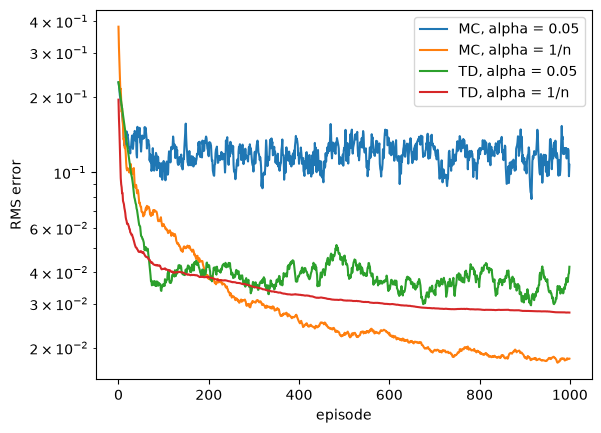

In [11]:
rng = np.random.default_rng(1)
long = {(m, name): np.mean([estimate(m, 0.05, 1000, rng, step) for _ in range(20)], axis=0)
        for m in ['MC', 'TD'] for name, step in [('alpha = 0.05', None), ('alpha = 1/n', lambda n: 1 / n)]}
for (m, name), c in long.items():
  plt.plot(c, label=f'{m}, {name}')
plt.yscale('log'); plt.xlabel('episode'); plt.ylabel('RMS error'); plt.legend()
{f'{m}, {name}': round(float(c[-50:].mean()), 4) for (m, name), c in long.items()}

**Conclusion** With a constant step size $\alpha = 0.05$, the errors stop decreasing (MC $0.118$, TD $0.034$ after $1000$ episodes): the estimates keep moving with the last episodes. With $\alpha_n = 1/n$, they keep decreasing ($0.018$ for MC, $0.028$ for TD): for MC, $1/n$ gives the empirical mean of the returns, which converges to the true value (law of large numbers); TD also converges under the Robbins–Monro conditions $\sum\alpha_n = \infty$, $\sum\alpha_n^2 < \infty$ (PC6). A constant step size is preferred when the problem is non-stationary (e.g. in control, where the policy changes).

---

## 4. SARSA and Q-learning

Without a model, control learns the action values $Q(s, a)$ from the transitions, while acting $\varepsilon$-greedily. After a transition $(s, a, r, s')$ and the choice of the next action $a'$:
- SARSA (on-policy) uses the target $r + \gamma Q(s', a')$: it learns the value of the $\varepsilon$-greedy policy it follows,
- Q-learning (off-policy) uses the target $r + \gamma\max_b Q(s', b)$: it learns the value of the greedy policy.

As in the lecture, we use $\varepsilon = 0.1$, $\alpha = 0.5$, no discount, and no slip.

**Question** *Predict before you run:* which method will collect more reward during learning? Implement both on `RL.make_env(max_steps=1000)` ($500$ episodes, ties broken at random, $Q$ initialized at $0$), average the reward per episode over $20$ runs, and plot it (smoothed over $10$ episodes). Draw the greedy paths of the learned $Q$ (averaged over the runs).

**Answer**

SARSA: mean reward per episode over the last 100 episodes -26.6, greedy path 17 steps
Q-learning: mean reward per episode over the last 100 episodes -50.5, greedy path 13 steps


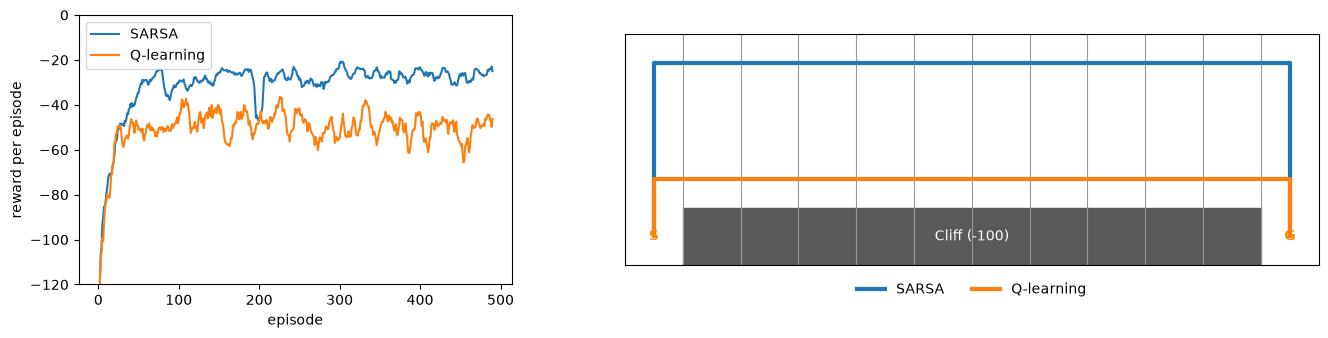

In [12]:
def epsilon_greedy(q, epsilon, rng):
  if rng.random() < epsilon:
    return int(rng.integers(NA))
  return int(rng.choice(np.flatnonzero(q == q.max())))

def td_control(method, n_episodes=500, alpha=0.5, epsilon=0.1, seed=0):
  rng, env = np.random.default_rng(seed), RL.make_env(max_steps=1000)
  Q, returns = np.zeros((NS, NA)), np.zeros(n_episodes)
  for e in range(n_episodes):
    s, _ = env.reset(seed=seed * 10_000 + e)
    a, done = epsilon_greedy(Q[s], epsilon, rng), False
    while not done:
      s2, r, terminated, truncated, _ = env.step(a)
      a2 = epsilon_greedy(Q[s2], epsilon, rng)
      target = r if terminated else r + (Q[s2, a2] if method == 'SARSA' else Q[s2].max())
      Q[s, a] += alpha * (target - Q[s, a])
      s, a, returns[e], done = s2, a2, returns[e] + r, terminated or truncated
  return Q, returns

results = {m: [td_control(m, seed=run) for run in range(20)] for m in ['SARSA', 'Q-learning']}
fig, axes = plt.subplots(1, 2, figsize=(16, 3.5), gridspec_kw=dict(width_ratios=[1, 1.6]))
paths = []
for m, color in [('SARSA', 'tab:blue'), ('Q-learning', 'tab:orange')]:
  curve = np.mean([r for _, r in results[m]], axis=0)
  axes[0].plot(np.convolve(curve, np.ones(10) / 10, mode='valid'), color=color, label=m)
  paths.append((RL.greedy_path(np.mean([q for q, _ in results[m]], axis=0).argmax(axis=1)), color, m))
  print(f'{m}: mean reward per episode over the last 100 episodes {curve[-100:].mean():.1f}, greedy path {len(paths[-1][0]) - 1} steps')
axes[0].set_ylim(-120, 0); axes[0].set_xlabel('episode'); axes[0].set_ylabel('reward per episode'); axes[0].legend()
RL.draw_grid(axes[1], paths=paths)

**Conclusion** SARSA collects more reward during learning (about $-27$ per episode against $-50$ for Q-learning), although Q-learning learns the optimal path along the cliff ($13$ steps) and SARSA the safe path along the top ($17$ steps). Q-learning learns the value of the greedy policy, but it acts $\varepsilon$-greedily: along the cliff, the random moves often make it fall. SARSA learns the value of the policy it actually follows, exploration included, and therefore avoids the cliff. The difference disappears if $\varepsilon$ goes to $0$.

---

## 5. Policy gradient: REINFORCE in PyTorch

A policy gradient method optimizes a parametrized policy directly. With a tabular softmax policy $\pi_\theta(a|s) \propto e^{\theta_{s,a}}$, the REINFORCE estimator of $\nabla_\theta J(\theta)$ for an episode $(s_0, a_0, r_1, \dots)$ is $\sum_t G\,\nabla_\theta\log\pi_\theta(a_t|s_t)$, with either the total return $G = G_0$ or, using causality, the *reward-to-go* $G = G_t = \sum_{t' \geq t} r_{t'+1}$ (PC6). In PyTorch, gradient descent uses the negative of this estimate, the gradient of the loss $-\sum_t G\log\pi_\theta(a_t|s_t)$, computed by automatic differentiation.

To keep the episodes short, they start from a random valid state and are cut after $100$ steps (no discount, no slip). The quality of a policy is measured exactly with the model: `expected_return` computes the expected sum of rewards over $100$ steps from S and averaged over the training start distribution (backward induction).

Training optimizes the average over random valid starting states. The return from S is a separate evaluation metric.

In [13]:
P0, R0 = RL.tabular_model(slip=0.0)
STARTS = [s for s in range(NS) if VALID[s] and s != GOAL]
def expected_return(theta, horizon=100):
  pi = torch.softmax(theta, dim=1).detach().numpy()
  P_pi, r_pi = np.einsum('sa,sat->st', pi, P0), (pi * R0).sum(axis=1)
  v = np.zeros(NS)
  for _ in range(horizon):
    v = r_pi + P_pi @ v
  return v[START], v[STARTS].mean()

**Question** Write a function sampling an episode with the policy $\text{softmax}(\theta)$ (return the states, the actions, the rewards, the final successor and the termination flags), and the REINFORCE loss with the full return or the reward-to-go. Train $\theta$ (initialized at $0$, plain SGD with step sizes $3\cdot10^{-4}$ for the full return and $10^{-3}$ for the reward-to-go) for $4000$ episodes, $3$ runs each, and plot the return from S every $100$ episodes. Report the final median from S and from a uniformly random valid nonterminal state. The optimum from S is $-13$.

**Answer**

197 s
shape: (2, 3)
┌──────────────┬─────────────────┬─────────────────────┐
│ estimator    ┆ expected return ┆ random-start return │
│ ---          ┆ ---             ┆ ---                 │
│ str          ┆ f64             ┆ f64                 │
╞══════════════╪═════════════════╪═════════════════════╡
│ reward-to-go ┆ -23.572791      ┆ -12.786485          │
│ full return  ┆ -99.575824      ┆ -37.905843          │
└──────────────┴─────────────────┴─────────────────────┘


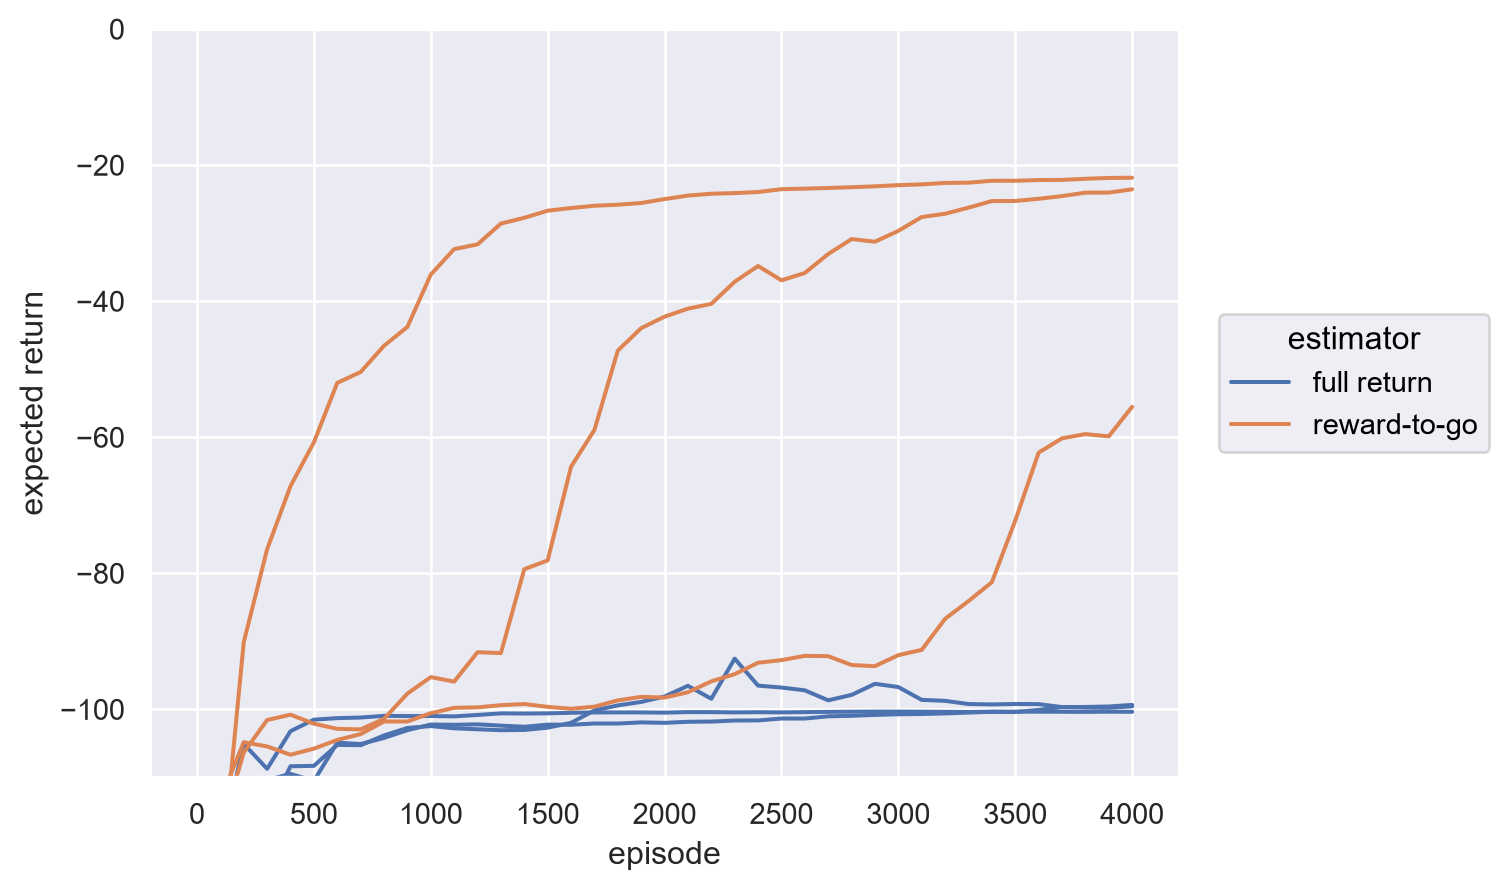

In [14]:
env = RL.make_env(max_steps=100)
def sample_episode(theta, rng):
  s = RL.reset_to(env, STARTS[rng.integers(len(STARTS))])
  states, actions, rewards, done = [], [], [], False
  probabilities = torch.softmax(theta, dim=1).detach().numpy()
  while not done:
    a = rng.choice(NA, p=probabilities[s])
    s2, r, terminated, truncated, _ = env.step(a)
    states.append(s); actions.append(a); rewards.append(r)
    s, done = s2, terminated or truncated
  return torch.tensor(states), torch.tensor(actions), torch.tensor(rewards, dtype=torch.float32), s, terminated, truncated

def reinforce_loss(theta, states, actions, rewards, reward_to_go):
  log_pi = torch.log_softmax(theta[states], dim=1)[torch.arange(len(actions)), actions]
  G = torch.flip(torch.cumsum(torch.flip(rewards, [0]), 0), [0]) if reward_to_go else rewards.sum().expand(len(rewards))
  return -(G * log_pi).sum()

def train_reinforce(reward_to_go, lr, n_episodes=4000, seed=0):
  rng = np.random.default_rng(seed)
  theta = torch.zeros(NS, NA, requires_grad=True)
  optimizer = torch.optim.SGD([theta], lr=lr)
  curve = []
  for e in range(n_episodes + 1):
    if e % 100 == 0:
      from_start, random_start = expected_return(theta)
      curve.append({'episode': e, 'expected return': from_start, 'random-start return': random_start})
    loss = reinforce_loss(theta, *sample_episode(theta, rng)[:3], reward_to_go)
    optimizer.zero_grad(); loss.backward(); optimizer.step()
  return curve

start = time.perf_counter()
curves = pl.concat([pl.DataFrame(train_reinforce(rtg, lr, seed=run)).with_columns(estimator=pl.lit(name), run=pl.lit(run))
                    for name, rtg, lr in [('full return', False, 3e-4), ('reward-to-go', True, 1e-3)] for run in range(3)])
print(f'{time.perf_counter() - start:.0f} s')
print(curves.filter(pl.col('episode') == 4000).group_by('estimator').agg(pl.col('expected return', 'random-start return').median()))
so.Plot(curves, x='episode', y='expected return', color='estimator', group='run').add(so.Line()).limit(y=(-110, 0))

**Conclusion** After 4000 episodes, median return from S is $-23.6$ with reward-to-go and $-99.6$ with the full return. Averaging over the random starts used for training gives $-12.8$ and $-37.9$, respectively. The learning rates differ. The next experiment measures gradient variance directly at a fixed policy.

---

**Question** At the initial policy ($\theta = 0$), sample $2000$ episodes and compute, for each of them, the coordinate $\partial/\partial\theta_{S,\text{up}}$ of the gradient of the REINFORCE objective (minus the gradient of the loss) with both estimators. Compare their means and standard deviations. Why is the reward-to-go legitimate, and why does it help?

**Answer**

In [15]:
rng = np.random.default_rng(0)
theta0 = torch.zeros(NS, NA, requires_grad=True)
coordinates = {'full return': [], 'reward-to-go': []}
for _ in range(2000):
  episode = sample_episode(theta0, rng)
  for name, rtg in [('full return', False), ('reward-to-go', True)]:
    (gradient,) = torch.autograd.grad(-reinforce_loss(theta0, *episode[:3], rtg), theta0)
    coordinates[name].append(gradient[START, UP].item())
{name: {'mean': np.mean(g), 'standard deviation': np.std(g)} for name, g in coordinates.items()}

{'full return': {'mean': np.float64(400.678625),
  'standard deviation': np.float64(2735.7472538479974)},
 'reward-to-go': {'mean': np.float64(396.67425),
  'standard deviation': np.float64(1560.0098328454337)}}

**Conclusion** Both estimators have the same mean (about $400$, up to the Monte Carlo noise: they estimate the same gradient), but the standard deviation of the reward-to-go estimator is about half that of the full return ($1560$ against $2740$). The reward-to-go is legitimate because an action cannot influence the past rewards: their terms have zero expectation (PC6), so removing them does not change the mean and reduced the measured variance for this coordinate. Both are still very noisy compared with their mean, which motivates the baselines of the *To go further* part.

---

## To go further

The following blocks are optional and independent: each of them only uses the objects defined in the core part. Their difficulty is marked by stars: ★ direct extension, ★★ new method, ★★★ longer or research-flavored.

| Block | Lecture | Stars |
|---|---|---|
| Multi-armed bandits | Bandits | ★★ |
| Monte Carlo control | Monte Carlo control | ★ |
| $n$-step TD | $n$-step methods and eligibility traces | ★★ |
| Maximization bias and double Q-learning | Q-learning, DQN overestimation | ★★ |
| Transfer to Taxi | Tabular methods | ★ |
| Baird's counterexample | The deadly triad | ★★ |
| Baseline and actor-critic | Policy gradient, actor-critic | ★★ |
| GRPO: group-relative advantages | LLMs: reasoning with verifiable rewards | ★★ |
| DQN on CartPole | Deep Q-networks | ★★ |
| PPO | Proximal policy optimization | ★★ |
| Preferences: reward model and DPO | RLHF and DPO | ★★ |
| A tiny agent with retrieval | The agent loop, RAG | ★★★ |

The packages used in these blocks (not needed for the core) are installed here:

In [16]:
import sys
!uv pip install --python "{sys.executable}" "gymnasium[classic-control]==1.2.*" "stable-baselines3==2.9.0" "transformers"

Using Python 3.12.14 environment at: ~\.venvs\apm50441
Checked 3 packages in 40ms


### Multi-armed bandits (★★)

A bandit is an MDP with a single state: at each step, the agent pulls one of $K$ arms and receives a noisy reward. The *regret* $\sum_t(\mu_\star - \mu_{A_t})$ measures the cost of learning. $\varepsilon$-greedy explores at a constant rate (linear regret), UCB plays $\arg\max_a\hat\mu_a + \sqrt{2\log t/N_a}$ (optimism in the face of uncertainty) and Thompson sampling plays the best arm of a sample of the posterior.

**Question** On the $10$-armed Gaussian testbed (means $\mu_a \sim \mathcal{N}(0, 1)$, unit noise, horizon $2000$, $100$ runs), compare the cumulative regret of $\varepsilon$-greedy ($\varepsilon = 0.1$), UCB and Thompson sampling (prior $\mathcal{N}(0, 1)$ on each mean, known unit noise).

**Answer**

{'epsilon-greedy': 403.5, 'UCB': 106.7, 'Thompson': 79.2}

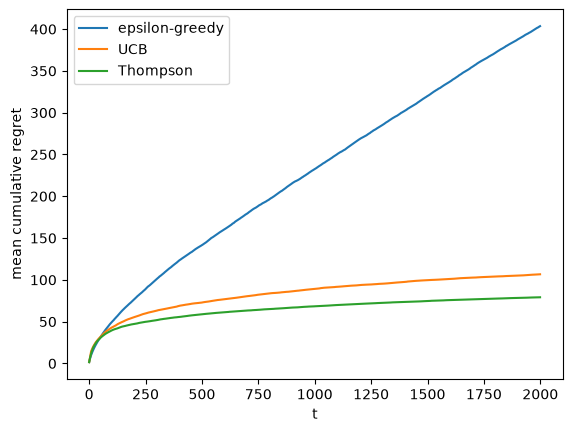

In [17]:
K, T, runs = 10, 2000, 100
rng = np.random.default_rng(0)
mu = rng.normal(size=(runs, K))
noise = rng.normal(size=(T, runs, K))
def bandit(choose):
  sums, counts, regret = np.zeros((runs, K)), np.zeros((runs, K)), np.zeros((T, runs))
  rng_ = np.random.default_rng(1)
  for t in range(T):
    a = choose(t, sums, counts, rng_)
    reward = mu[np.arange(runs), a] + noise[t, np.arange(runs), a]
    sums[np.arange(runs), a] += reward
    counts[np.arange(runs), a] += 1
    regret[t] = mu.max(axis=1) - mu[np.arange(runs), a]
  return regret.cumsum(axis=0).mean(axis=1)
def epsilon_greedy_arm(t, sums, counts, rng_):
  means = sums / np.maximum(counts, 1)
  greedy_arm = (means + 1e-9 * rng_.random(means.shape)).argmax(axis=1)
  return np.where(rng_.random(runs) < 0.1, rng_.integers(K, size=runs), greedy_arm)
def ucb_arm(t, sums, counts, rng_):
  if t < K:
    return np.full(runs, t)
  return (sums / counts + np.sqrt(2 * np.log(t) / counts)).argmax(axis=1)
def thompson_arm(t, sums, counts, rng_):
  posterior_mean, posterior_sd = sums / (counts + 1), 1 / np.sqrt(counts + 1)
  return (posterior_mean + posterior_sd * rng_.normal(size=(runs, K))).argmax(axis=1)
regrets = {name: bandit(f) for name, f in [('epsilon-greedy', epsilon_greedy_arm), ('UCB', ucb_arm), ('Thompson', thompson_arm)]}
for name, r in regrets.items():
  plt.plot(r, label=name)
plt.xlabel('t'); plt.ylabel('mean cumulative regret'); plt.legend()
{name: round(float(r[-1]), 1) for name, r in regrets.items()}

**Conclusion** After $2000$ steps, $\varepsilon$-greedy has a mean regret of $404$: it keeps exploring at a constant rate, so its regret grows linearly. UCB ($107$) and Thompson sampling ($79$) explore only while the uncertainty on an arm makes it possibly optimal, and their regret grows logarithmically. Thompson sampling, the Bayesian approach, is the best here. The same exploration/exploitation trade-off appears in recommendation (Lab 5) and in the exploration of RL agents.

---

### Monte Carlo control (★)

Monte Carlo control alternates the evaluation of $Q$ by averaging the returns of complete episodes and an $\varepsilon$-greedy improvement. It needs no bootstrapping, but each update waits for the end of the episode.

**Question** Implement on-policy every-visit MC control on Cliff Walking ($\varepsilon = 0.1$, episodes from S cut after $200$ steps, $2000$ episodes), with $Q(s, a)$ updated towards the observed returns either by their average (step size $1/n$) or with a constant step size $\alpha = 0.1$. Which paths are learned? Compare with SARSA and Q-learning.

**Answer**

{'average of the returns': {'greedy path length': 21,
  'reaches the goal': True,
  'mean reward per episode, last 200 episodes': np.float64(-36.545)},
 'constant step size 0.1': {'greedy path length': 19,
  'reaches the goal': True,
  'mean reward per episode, last 200 episodes': np.float64(-43.765)}}

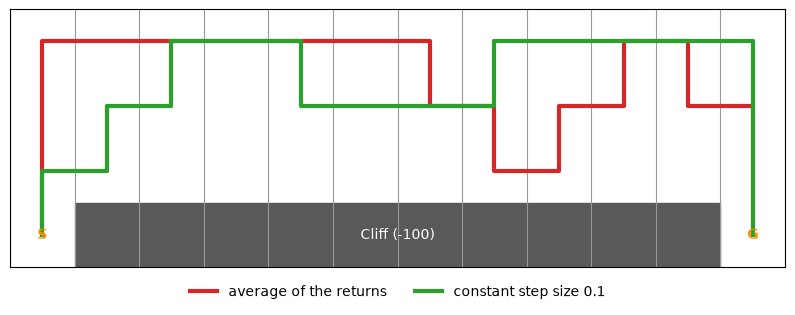

In [18]:
def mc_control(n_episodes=2000, alpha=None, epsilon=0.1, seed=0):
  rng, env_mc = np.random.default_rng(seed), RL.make_env(max_steps=200)
  Q, counts, returns = np.zeros((NS, NA)), np.zeros((NS, NA)), []
  for e in range(n_episodes):
    s, _ = env_mc.reset(seed=e)
    trajectory, done = [], False
    while not done:
      a = epsilon_greedy(Q[s], epsilon, rng)
      s2, r, terminated, truncated, _ = env_mc.step(a)
      trajectory.append((s, a, r))
      s, done = s2, terminated or truncated
    G = 0.0
    for s, a, r in reversed(trajectory):
      G += r
      counts[s, a] += 1
      Q[s, a] += (alpha or 1 / counts[s, a]) * (G - Q[s, a])
    returns.append(sum(r for _, _, r in trajectory))
  return Q, np.array(returns)
results_mc = {}
for name, alpha in [('average of the returns', None), ('constant step size 0.1', 0.1)]:
  Q_mc, returns_mc = mc_control(alpha=alpha)
  path_mc = RL.greedy_path(Q_mc.argmax(axis=1))
  results_mc[name] = (path_mc, {'greedy path length': len(path_mc) - 1, 'reaches the goal': path_mc[-1] == GOAL,
                                'mean reward per episode, last 200 episodes': returns_mc[-200:].mean()})
fig, ax = plt.subplots(figsize=(10, 3.5))
RL.draw_grid(ax, paths=[(path, color, name) for (name, (path, _)), color in zip(results_mc.items(), ['tab:red', 'tab:green'])])
{name: summary for name, (_, summary) in results_mc.items()}

**Conclusion** Both versions of MC control learn to reach the goal while staying away from the cliff, but with irregular paths ($21$ steps with the averages of the returns, $19$ with a constant step size), and a mean reward of about $-40$ per episode during learning, worse than SARSA. MC waits for the end of each episode and its returns are very noisy (a fall early in an episode penalizes all the actions of the episode), so that many episodes are needed to rank the actions correctly; with long episodes (e.g. capped at $1000$ steps), the averages of the returns of the first episodes dominate for a very long time and the method can fail to learn. TD methods bootstrap and learn during the episode.

---

### $n$-step TD (★★)

$n$-step TD uses the target $r_{t+1} + \dots + r_{t+n} + V(s_{t+n})$: $n = 1$ is TD(0), $n = \infty$ is MC. Intermediate values often work best (Sutton and Barto, Figure 7.2).

**Question** On the random walk with $19$ states (`RL.random_walk_episode(rng, n=19)`, true values $(s+1)/20$), compute the RMS error over the first $10$ episodes (averaged over $100$ runs, values initialized at $0.5$) of $n$-step TD for $n \in \{1, 2, 4, 8, 16, 64\}$ as a function of $\alpha$.

**Answer**

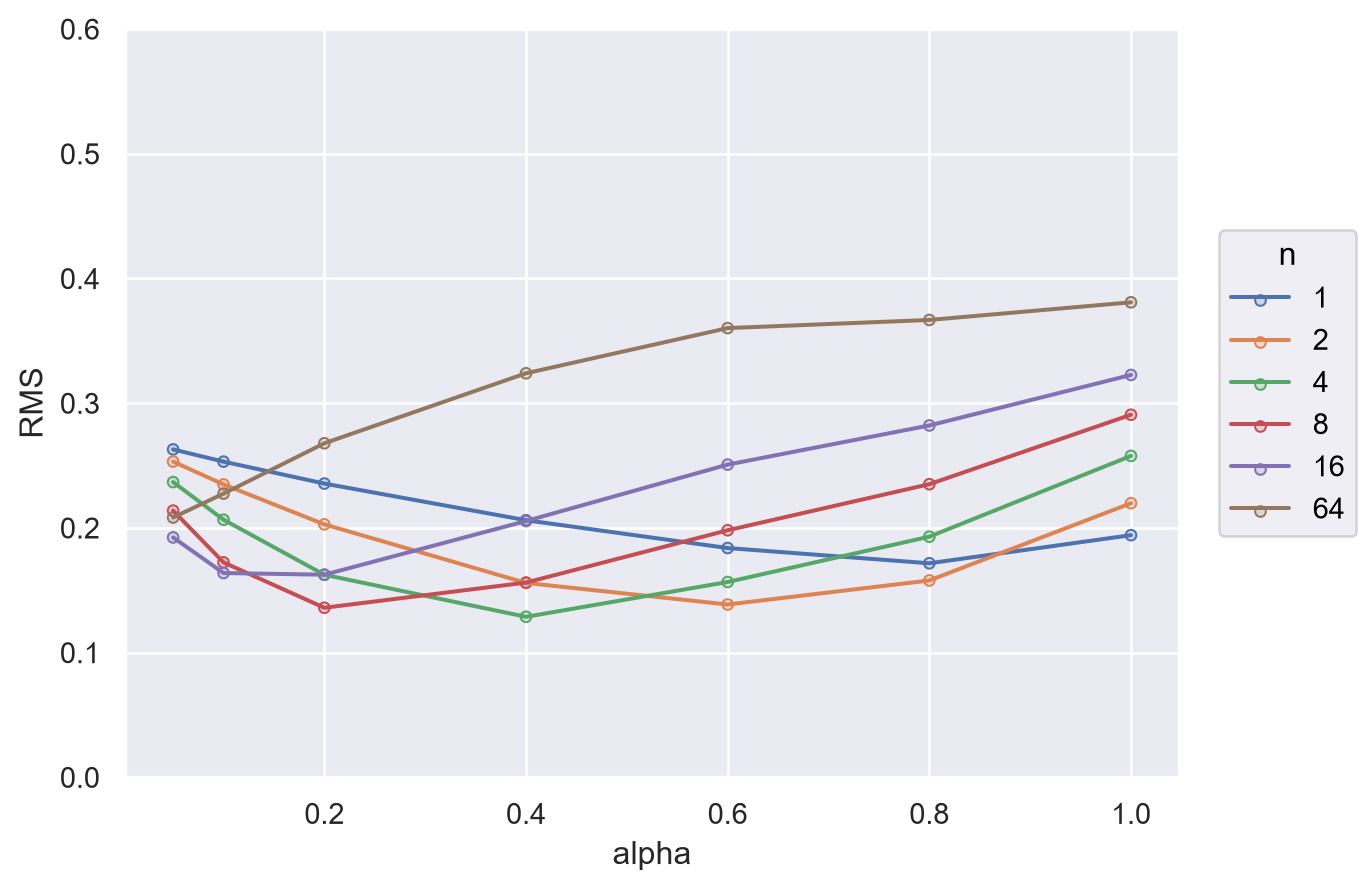

In [19]:
V_true19 = np.arange(1, 20) / 20
def n_step_td(n, alpha, rng, n_episodes=10):
  V, errors = np.full(19, 0.5), []
  for _ in range(n_episodes):
    transitions = RL.random_walk_episode(rng, n=19)
    states, rewards = [s for s, _, _ in transitions], [r for _, r, _ in transitions]
    T_ = len(transitions)
    for t in range(T_):
      end = min(t + n, T_)
      G = sum(rewards[t:end]) + (V[states[end]] if end < T_ else 0.0)
      V[states[t]] += alpha * (G - V[states[t]])
    errors.append(np.sqrt(np.mean((V - V_true19) ** 2)))
  return np.mean(errors)
rng = np.random.default_rng(0)
alphas_n = [0.05, 0.1, 0.2, 0.4, 0.6, 0.8, 1.0]
table = pl.DataFrame([{'n': n, 'alpha': a, 'RMS': np.mean([n_step_td(n, a, rng) for _ in range(100)])}
                      for n in [1, 2, 4, 8, 16, 64] for a in alphas_n])
so.Plot(table, x='alpha', y='RMS', color=table['n'].cast(pl.String)).add(so.Line()).add(so.Dots()).limit(y=(0, 0.6)).label(color='n')

In [20]:
table.group_by('n').agg(pl.col('RMS').min().alias('best RMS'), pl.col('alpha').get(pl.col('RMS').arg_min()).alias('best alpha')).sort('n')

n,best RMS,best alpha
i64,f64,f64
1,0.17157,0.8
2,0.138523,0.6
4,0.128642,0.4
8,0.135899,0.2
16,0.162399,0.2
64,0.208286,0.05


**Conclusion** The best error is obtained for intermediate values of $n$: $0.129$ for $n = 4$ (with $\alpha = 0.4$), against $0.172$ for TD(0) ($n = 1$) and $0.208$ for $n = 64$ (almost MC). Larger $n$ need smaller step sizes, as the targets are noisier. $n$ interpolates between the bias of bootstrapping and the variance of the full returns, as in Sutton and Barto's Figure 7.2; TD($\lambda$) averages over all the $n$.

---

### Maximization bias and double Q-learning (★★)

The target $\max_b Q(s', b)$ of Q-learning is a maximum of noisy estimates, hence biased upwards: $\mathbb{E}[\max_b \hat Q(b)] \geq \max_b\mathbb{E}[\hat Q(b)]$. Double Q-learning keeps two tables, selects the action with one and evaluates it with the other. In the small MDP of Sutton and Barto (Example 6.7), from A the action *right* ends the episode with reward $0$, while *left* leads to B, from which $10$ actions end the episode with a reward $\mathcal{N}(-0.1, 1)$: going left is a mistake.

**Question** Run Q-learning and double Q-learning ($\varepsilon = 0.1$, $\alpha = 0.1$, no discount, $300$ episodes, $1000$ runs) on this MDP, and plot the proportion of *left* actions in A along the episodes. Check first the bias numerically: the mean of the maximum of $10$ sample means of $5$ draws of $\mathcal{N}(-0.1, 1)$.

**Answer**

E[max of 10 sample means] = 0.5912643020574322 (true max: -0.1)


{'Q-learning': {'first 20 episodes': np.float64(0.8047500000000001),
  'last 50 episodes': np.float64(0.12736)},
 'double Q-learning': {'first 20 episodes': np.float64(0.44625000000000004),
  'last 50 episodes': np.float64(0.06772)}}

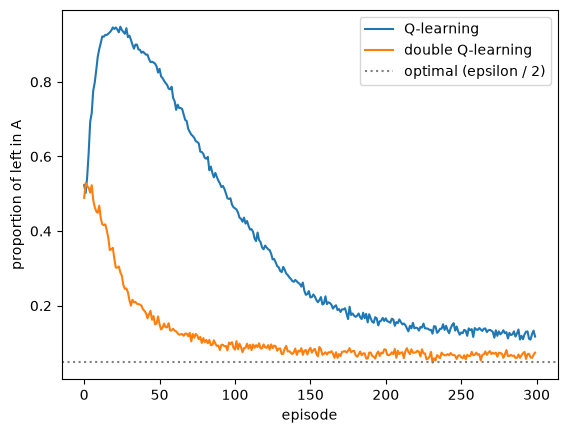

In [21]:
rng = np.random.default_rng(0)
print('E[max of 10 sample means] =', rng.normal(-0.1, 1, size=(10_000, 10, 5)).mean(axis=2).max(axis=1).mean(), '(true max: -0.1)')
def maximization_bias(double, n_episodes=300, runs=1000, alpha=0.1, epsilon=0.1, seed=0):
  rng = np.random.default_rng(seed)
  left = np.zeros(n_episodes)
  for run in range(runs):
    QA1, QA2, QB1, QB2 = np.zeros(2), np.zeros(2), np.zeros(10), np.zeros(10)   # A: 0 = left, 1 = right
    for e in range(n_episodes):
      qa = QA1 + QA2 if double else QA1
      a = int(rng.integers(2)) if rng.random() < epsilon else int(rng.choice(np.flatnonzero(qa == qa.max())))
      left[e] += a == 0
      if a == 1:                                                 # right: terminal, reward 0
        if double and rng.random() < 0.5:
          QA2[1] += alpha * (0 - QA2[1])
        else:
          QA1[1] += alpha * (0 - QA1[1])
        continue
      if not double:                                             # left: reward 0, then B
        QA1[0] += alpha * (QB1.max() - QA1[0])
        qb = QB1
      elif rng.random() < 0.5:
        QA1[0] += alpha * (QB2[QB1.argmax()] - QA1[0]); qb = QB1 + QB2
      else:
        QA2[0] += alpha * (QB1[QB2.argmax()] - QA2[0]); qb = QB1 + QB2
      b = int(rng.integers(10)) if rng.random() < epsilon else int(rng.choice(np.flatnonzero(qb == qb.max())))
      r = rng.normal(-0.1, 1)
      if double and rng.random() < 0.5:
        QB2[b] += alpha * (r - QB2[b])
      else:
        QB1[b] += alpha * (r - QB1[b])
  return left / runs
curves_bias = {'Q-learning': maximization_bias(False), 'double Q-learning': maximization_bias(True)}
for name, c in curves_bias.items():
  plt.plot(c, label=name)
plt.axhline(0.05, color='gray', ls=':', label='optimal (epsilon / 2)')
plt.xlabel('episode'); plt.ylabel('proportion of left in A'); plt.legend()
{name: {'first 20 episodes': c[:20].mean(), 'last 50 episodes': c[-50:].mean()} for name, c in curves_bias.items()}

**Conclusion** The maximum of $10$ sample means of a distribution of mean $-0.1$ has an expectation of $0.59$: maximizing over noisy estimates is strongly biased upwards. In the MDP, Q-learning goes left (a mistake) in $80\%$ of the first $20$ episodes, as the overestimated value of B makes the left action attractive, and still in $13\%$ of the last episodes. Double Q-learning goes left much less ($45\%$ at the beginning, $7\%$ at the end, close to the $5\%$ forced by the exploration): selecting the action with one table and evaluating it with the other removes the bias. DQN uses the same idea with its target network (double DQN).

---

### Transfer to Taxi (★)

`Taxi-v3` is another tabular environment: $500$ states (taxi position, passenger location, destination) and $6$ actions (moves, pick up, drop off), reward $-1$ per step, $+20$ for a correct drop-off and $-10$ for an illegal pick-up or drop-off.

**Question** Adapt your Q-learning to `gym.make('Taxi-v3')` ($\varepsilon = 0.1$, $\alpha = 0.5$, $\gamma = 0.99$, $3000$ episodes), plot the reward per episode, and evaluate the greedy policy on $100$ new episodes.

**Answer**

{'mean reward of the greedy policy': np.float64(7.86),
 'success rate': np.float64(1.0)}

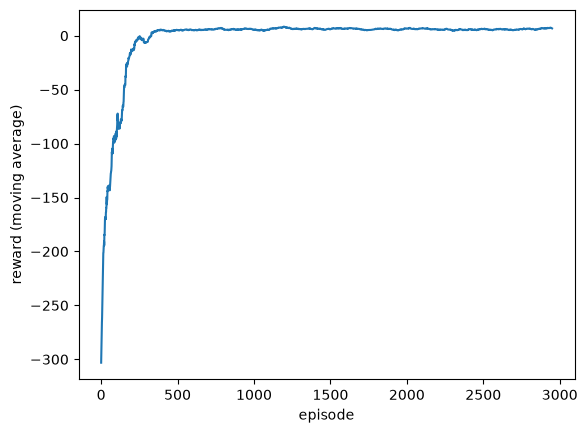

In [22]:
taxi = gym.make('Taxi-v3')
rng = np.random.default_rng(0)
Q_taxi, taxi_returns = np.zeros((taxi.observation_space.n, taxi.action_space.n)), []
for e in range(3000):
  s, _ = taxi.reset(seed=e)
  total, done = 0, False
  while not done:
    a = epsilon_greedy(Q_taxi[s], 0.1, rng)
    s2, r, terminated, truncated, _ = taxi.step(a)
    Q_taxi[s, a] += 0.5 * (r + (0 if terminated else 0.99 * Q_taxi[s2].max()) - Q_taxi[s, a])
    s, total, done = s2, total + r, terminated or truncated
  taxi_returns.append(total)
plt.plot(np.convolve(taxi_returns, np.ones(50) / 50, mode='valid')); plt.xlabel('episode'); plt.ylabel('reward (moving average)')
greedy_returns = []
for e in range(100):
  s, _ = taxi.reset(seed=100_000 + e)
  total, done = 0, False
  while not done:
    s, r, terminated, truncated, _ = taxi.step(int(Q_taxi[s].argmax()))
    total, done = total + r, terminated or truncated
  greedy_returns.append(total)
{'mean reward of the greedy policy': np.mean(greedy_returns), 'success rate': np.mean(np.array(greedy_returns) > 0)}

**Conclusion** The same Q-learning, unchanged, learns Taxi: the reward per episode goes from about $-300$ to positive values within about $300$ episodes, and the greedy policy succeeds in all the $100$ test episodes, with a mean reward of $7.9$ (about $13$ moves to pick up and drop off the passenger). Tabular methods only need the states and the actions to be enumerable; their limit is the number of states.

---

### Baird's counterexample (★★)

The *deadly triad* (function approximation, bootstrapping and off-policy learning) can make TD diverge. Baird's counterexample (Sutton and Barto, Example 11.1): $7$ states, all rewards $0$ (so $v_\pi = 0$), $\gamma = 0.99$; the behavior policy goes to one of the $6$ upper states with probability $6/7$ and to state $7$ with probability $1/7$, the target policy always goes to state $7$ (importance ratio $7$ or $0$). The linear features are $v(i) = 2w_i + w_8$ for $i \leq 6$ and $v(7) = w_7 + 2w_8$: $w = 0$ is a perfect fit.

**Question** Run off-policy semi-gradient TD(0) ($\alpha = 0.01$, $w_0 = (1, 1, 1, 1, 1, 1, 10, 1)$, $1000$ steps) with these linear features and with tabular features (same initial values), and plot the largest $|v(s)|$ along the steps. Then run the linear version *on-policy* (transitions drawn from the target policy... and from the behavior policy, without importance ratio).

**Answer**

{'linear, off-policy': 695.593503081741,
 'tabular, off-policy': 11.841401502740117,
 'linear, on the behavior policy': 1.755756497532233}

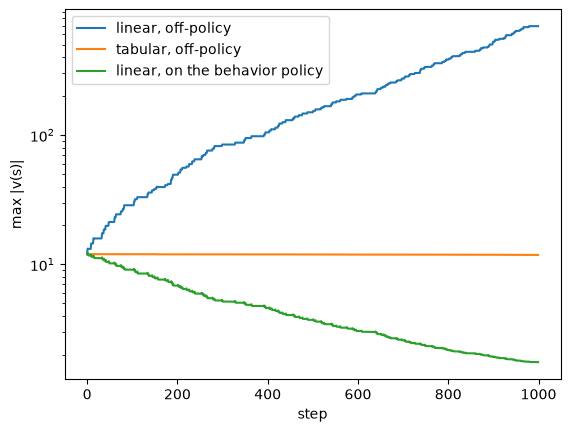

In [23]:
phi_linear = np.zeros((7, 8))
for i in range(6):
  phi_linear[i, i], phi_linear[i, 7] = 2, 1
phi_linear[6, 6], phi_linear[6, 7] = 1, 2
w0 = np.array([1, 1, 1, 1, 1, 1, 10, 1], dtype=float)
def semi_gradient_td(phi, w0, off_policy=True, n_steps=1000, alpha=0.01, gamma_b=0.99, seed=0):
  rng = np.random.default_rng(seed)
  w, s, largest = w0.copy(), int(rng.integers(7)), []
  for _ in range(n_steps):
    solid = rng.random() < 1 / 7
    s2 = 6 if solid else int(rng.integers(6))
    rho = (7.0 if solid else 0.0) if off_policy else 1.0
    delta = gamma_b * phi[s2] @ w - phi[s] @ w
    w += alpha * rho * delta * phi[s]
    s = s2
    largest.append(np.abs(phi @ w).max())
  return np.array(largest)
runs_baird = {'linear, off-policy': semi_gradient_td(phi_linear, w0), 'tabular, off-policy': semi_gradient_td(np.eye(7), phi_linear @ w0),
              'linear, on the behavior policy': semi_gradient_td(phi_linear, w0, off_policy=False)}
for name, c in runs_baird.items():
  plt.semilogy(c, label=name)
plt.xlabel('step'); plt.ylabel('max |v(s)|'); plt.legend()
{name: float(c[-1]) for name, c in runs_baird.items()}

**Conclusion** With linear features and off-policy updates, the value estimates diverge ($\max|v| \approx 700$ after $1000$ steps, and growing), although the true values are $0$ and a perfect fit $w = 0$ exists. With tabular features (no generalization between states), the same off-policy updates stay bounded, and with linear features but on the behavior policy's own distribution (no importance ratio), the estimates decrease towards $0$. Each element of the triad alone is harmless; the combination of function approximation, bootstrapping and off-policy learning is not (the deadly triad), which is why DQN needs a target network and a replay buffer to be stable.

---

### Baseline and actor-critic (★★)

Subtracting a baseline $b(s_t)$ from the reward-to-go does not bias the policy gradient (PC6) and can reduce its variance; with a learned value $V(s_t)$ as baseline, the advantage $G_t - V(s_t)$ measures whether the action was better than usual. An *actor-critic* replaces $G_t$ by the TD target $r_{t+1} + \gamma V(s_{t+1})$ and uses a one-step value estimate for each transition.

**Question** With $\gamma = 0.99$, compare on Cliff Walking ($2000$ episodes, $3$ runs, same episodes as in the core part) the reward-to-go REINFORCE, REINFORCE with a tabular value baseline (step size $0.1$ for $V$), and the one-step actor-critic (critic step size $0.1$). Measure the policies with the exact discounted value from S.

**Answer**

shape: (3, 2)
┌──────────────┬──────────────┐
│ variant      ┆ value from S │
│ ---          ┆ ---          │
│ str          ┆ f64          │
╞══════════════╪══════════════╡
│ actor-critic ┆ -20.875584   │
│ + baseline   ┆ -29.313324   │
│ reward-to-go ┆ -101.139328  │
└──────────────┴──────────────┘


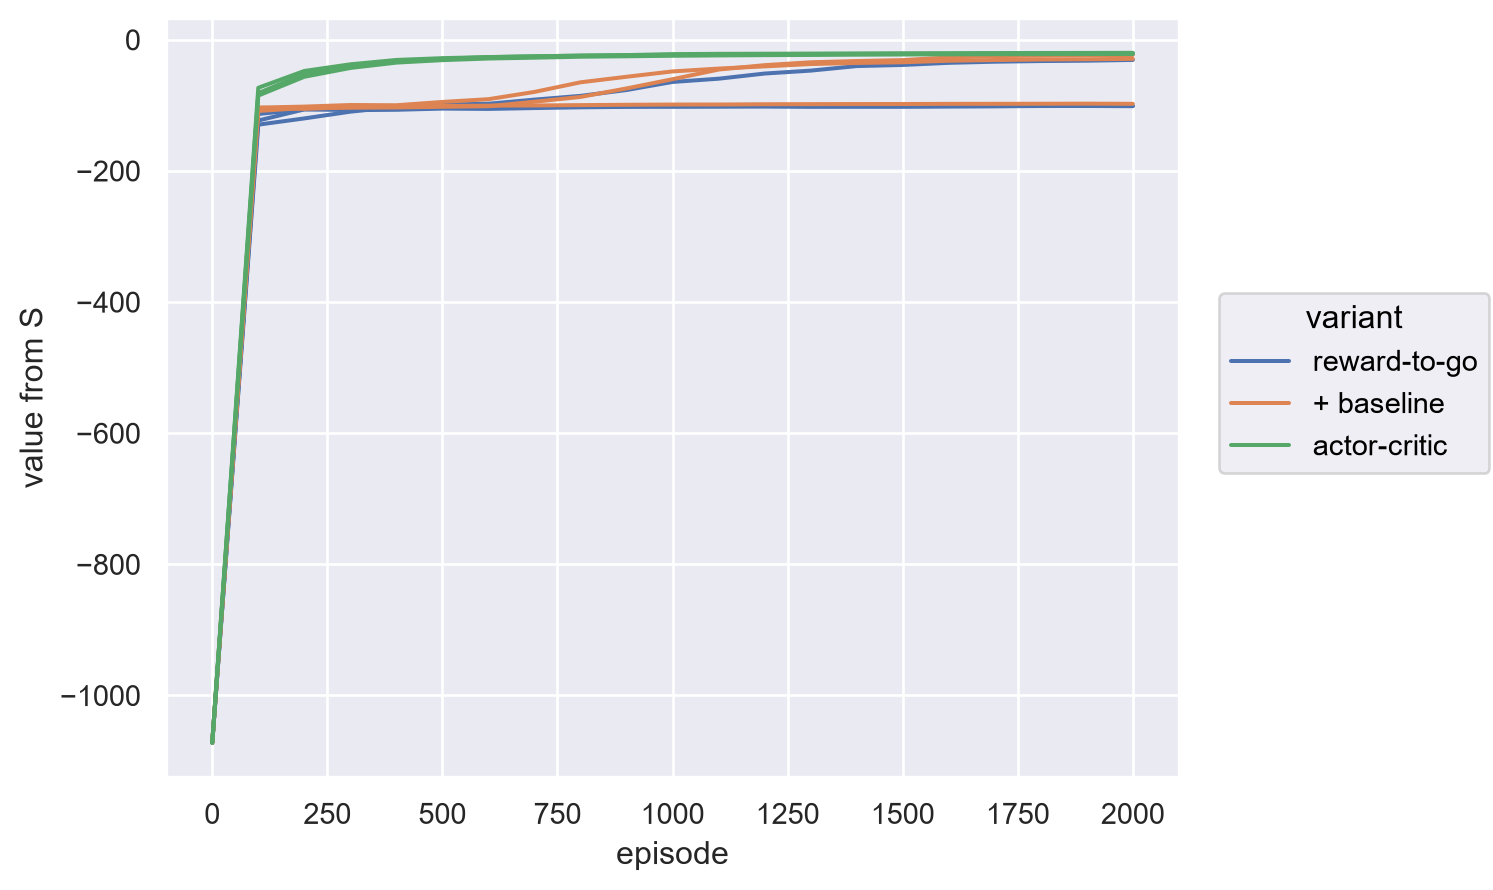

In [24]:
def discounted_value(theta, gamma_d=0.99):
  pi = torch.softmax(theta, dim=1).detach().numpy()
  P_pi, r_pi = np.einsum('sa,sat->st', pi, P0), (pi * R0).sum(axis=1)
  return np.linalg.solve(np.eye(NS) - gamma_d * P_pi, r_pi)[START]
def train_variant(variant, lr, n_episodes=2000, gamma_d=0.99, critic_lr=0.1, seed=0):
  rng = np.random.default_rng(seed)
  theta, V = torch.zeros(NS, NA, requires_grad=True), np.zeros(NS)
  optimizer, curve = torch.optim.SGD([theta], lr=lr), []
  for e in range(n_episodes + 1):
    if e % 100 == 0:
      curve.append({'episode': e, 'value from S': discounted_value(theta, gamma_d)})
    states, actions, rewards, successor, terminated, truncated = sample_episode(theta, rng)
    s_np, r_np = states.numpy(), rewards.numpy()
    discounts = gamma_d ** np.arange(len(r_np))
    G = np.array([np.sum(r_np[t:] * discounts[:len(r_np) - t]) for t in range(len(r_np))])
    if variant == 'reward-to-go':
      weights = G
    elif variant == '+ baseline':
      weights = G - V[s_np]
      for s, g in zip(s_np, G):
        V[s] += critic_lr * (g - V[s])
    else:                                                      # one-step actor-critic, online critic
      next_values = np.append(V[s_np[1:]], 0.0 if terminated else V[successor])
      weights = r_np + gamma_d * next_values - V[s_np]
      for s, delta in zip(s_np, weights):
        V[s] += critic_lr * delta
    log_pi = torch.log_softmax(theta[states], dim=1)[torch.arange(len(actions)), actions]
    loss = -(torch.tensor(weights * discounts, dtype=torch.float32) * log_pi).sum()
    optimizer.zero_grad(); loss.backward(); optimizer.step()
  return curve
variants = pl.concat([pl.DataFrame(train_variant(v, lr, seed=run)).with_columns(variant=pl.lit(v), run=pl.lit(run))
                      for v, lr in [('reward-to-go', 1e-3), ('+ baseline', 3e-3), ('actor-critic', 3e-3)] for run in range(3)])
print(variants.filter(pl.col('episode') == 2000).group_by('variant').agg(pl.col('value from S').median()))
so.Plot(variants, x='episode', y='value from S', color='variant', group='run').add(so.Line())

**Conclusion** After 2000 episodes the median discounted value from S is $-20.9$ for actor–critic, $-29.3$ for REINFORCE with a baseline and $-101.1$ for reward-to-go alone. The critic uses the observed successor at a time limit and a zero continuation value at the goal. Monte Carlo returns stop at the time limit. The curves compare complete training settings, including different learning rates. The final returns alone cannot quantify gradient variance.

---

### GRPO: group-relative advantages (★★)

To fine-tune language models with verifiable rewards, GRPO (DeepSeek, 2024) avoids learning a critic: it samples a *group* of $G$ answers to the same prompt and uses as advantage the reward normalized within the group, $A_i = (r_i - \bar r)/s_r$. RLOO uses $r_i - \frac{1}{G-1}\sum_{j\neq i}r_j$, an unbiased leave-one-out baseline. The same idea applies to our episodes: the "prompt" is the start state, the "answer" an episode.

**Question** Train the tabular softmax policy on Cliff Walking with groups of $G = 8$ episodes from the same random start state (each episode weighted by its group advantage, the same for all its steps), with the GRPO and the RLOO advantages, and with the raw return (the full-return REINFORCE of the core part), for $1000$ groups ($8000$ episodes, $2$ runs).

**Answer**

shape: (3, 2)
┌─────────────┬─────────────────┐
│ method      ┆ expected return │
│ ---         ┆ ---             │
│ str         ┆ f64             │
╞═════════════╪═════════════════╡
│ RLOO        ┆ -26.417817      │
│ GRPO        ┆ -17.729796      │
│ full return ┆ -101.678347     │
└─────────────┴─────────────────┘


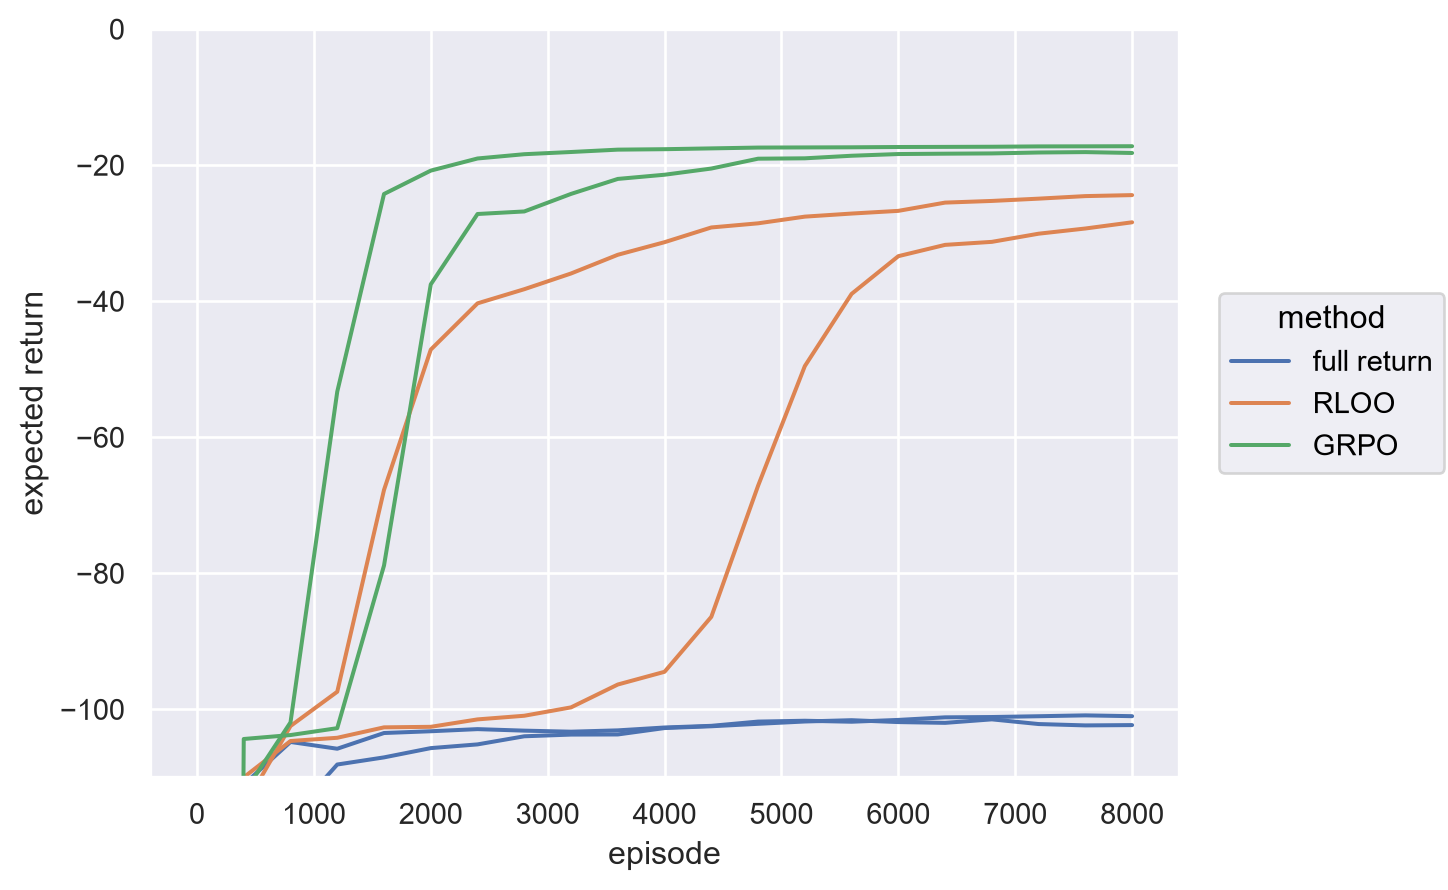

In [25]:
def train_group(advantage, lr, n_groups=1000, G=8, seed=0):
  rng = np.random.default_rng(seed)
  theta = torch.zeros(NS, NA, requires_grad=True)
  optimizer, curve = torch.optim.SGD([theta], lr=lr), []
  for g in range(n_groups + 1):
    if g % 50 == 0:
      curve.append({'episode': g * G, 'expected return': expected_return(theta)[0]})
    start_state, losses, returns_g, log_pis = STARTS[rng.integers(len(STARTS))], [], [], []
    for _ in range(G):
      RL.reset_to(env, start_state)
      states, actions, rewards, s, done = [], [], [], start_state, False
      probabilities = torch.softmax(theta, dim=1).detach().numpy()
      while not done:
        a = rng.choice(NA, p=probabilities[s])
        s2, r, terminated, truncated, _ = env.step(a)
        states.append(s); actions.append(a); rewards.append(r)
        s, done = s2, terminated or truncated
      returns_g.append(sum(rewards))
      log_pis.append(torch.log_softmax(theta[torch.tensor(states)], dim=1)[torch.arange(len(actions)), torch.tensor(actions)].sum())
    r_g = np.array(returns_g)
    if advantage == 'GRPO':
      A = (r_g - r_g.mean()) / (r_g.std() + 1e-8)
    elif advantage == 'RLOO':
      A = r_g - (r_g.sum() - r_g) / (G - 1)
    else:                                                           # raw return: REINFORCE without baseline
      A = r_g
    loss = -sum(a_i * lp for a_i, lp in zip(A, log_pis)) / G
    optimizer.zero_grad(); loss.backward(); optimizer.step()
  return curve
groups = pl.concat([pl.DataFrame(train_group(adv, lr, seed=run)).with_columns(method=pl.lit(adv), run=pl.lit(run))
                    for adv, lr in [('full return', 1e-3), ('RLOO', 3e-3), ('GRPO', 0.5)] for run in range(2)])
print(groups.filter(pl.col('episode') == 8000).group_by('method').agg(pl.col('expected return').median()))
so.Plot(groups, x='episode', y='expected return', color='method', group='run').add(so.Line()).limit(y=(-110, 0))

**Conclusion** In $8000$ episodes, the REINFORCE with the raw episode return does not learn (about $-102$), while the group baselines make the policy improve in these runs: RLOO reaches about $-26$ and GRPO about $-18$ (the optimum is $-13$). Comparing the returns of $8$ episodes from the same start state tells which episodes were better *than the others from the same situation*, without learning a value function; the normalization of GRPO also makes the step size independent of the scale of the rewards. RLOO preserves the expected gradient conditional on the start. Division by the random group standard deviation can change its expected direction; constant-reward groups contribute zero. The learning rates also differ. This is why these methods are used to fine-tune language models, where learning a critic as large as the model would be expensive.

---

### DQN on CartPole (★★)

With a large or continuous state space, $Q$ is approximated by a neural network. DQN (Mnih et al., 2015) stabilizes the Q-learning of a network with an *experience replay* buffer (decorrelated mini-batches of past transitions) and a *target network* (a frozen copy, updated periodically, to compute the targets). `CartPole-v1`: keep a pole balanced on a cart (state of dimension $4$, $2$ actions, reward $+1$ per step, at most $500$ steps).

**Question** Implement DQN (network $4 \to 64 \to 64 \to 2$, Adam with learning rate $10^{-3}$, buffer of $10\,000$ transitions, mini-batches of $64$, $\gamma = 0.99$, $\varepsilon$ decreasing linearly from $1$ to $0.05$ over $10\,000$ steps, target network updated every $500$ steps) for $30\,000$ steps, and plot the length of the episodes.

**Answer**

{'episodes': 379,
 'mean length of the last 20 episodes': np.float64(167.05),
 'time (s)': 63.26746810000623}

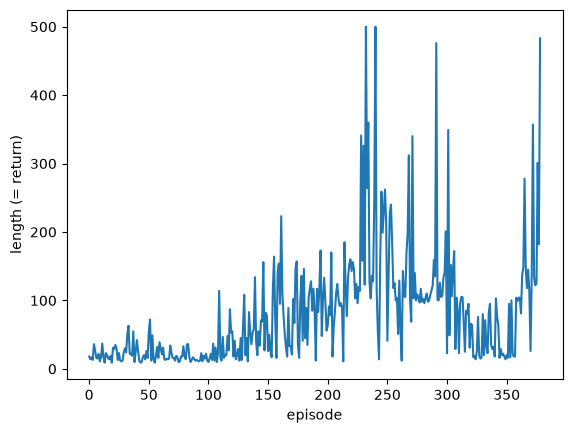

In [26]:
cartpole = gym.make('CartPole-v1')
torch.manual_seed(0)
rng = np.random.default_rng(0)
def q_network():
  return torch.nn.Sequential(torch.nn.Linear(4, 64), torch.nn.ReLU(), torch.nn.Linear(64, 64), torch.nn.ReLU(), torch.nn.Linear(64, 2))
q_net, target_net = q_network(), q_network()
target_net.load_state_dict(q_net.state_dict())
optimizer = torch.optim.Adam(q_net.parameters(), lr=1e-3)
buffer = {'s': np.zeros((10_000, 4), np.float32), 'a': np.zeros(10_000, np.int64), 'r': np.zeros(10_000, np.float32),
          's2': np.zeros((10_000, 4), np.float32), 'done': np.zeros(10_000, np.float32)}
lengths, length, size = [], 0, 0
s, _ = cartpole.reset(seed=0)
start = time.perf_counter()
for step in range(30_000):
  epsilon = max(0.05, 1 - step / 10_000)
  if rng.random() < epsilon:
    a = int(rng.integers(2))
  else:
    with torch.no_grad():
      a = int(q_net(torch.tensor(s, dtype=torch.float32)).argmax())
  s2, r, terminated, truncated, _ = cartpole.step(a)
  k = step % 10_000
  buffer['s'][k], buffer['a'][k], buffer['r'][k], buffer['s2'][k], buffer['done'][k] = s, a, r, s2, terminated
  size, length = min(size + 1, 10_000), length + 1
  s = s2
  if terminated or truncated:
    lengths.append(length); length = 0
    s, _ = cartpole.reset()
  if size >= 1000:
    idx = rng.integers(size, size=64)
    S, A, Rw, S2, D = (torch.tensor(buffer[key][idx]) for key in ['s', 'a', 'r', 's2', 'done'])
    with torch.no_grad():
      target = Rw + 0.99 * (1 - D) * target_net(S2).max(dim=1).values
    loss = torch.nn.functional.smooth_l1_loss(q_net(S).gather(1, A[:, None])[:, 0], target)
    optimizer.zero_grad(); loss.backward(); optimizer.step()
  if step % 500 == 0:
    target_net.load_state_dict(q_net.state_dict())
plt.plot(lengths); plt.xlabel('episode'); plt.ylabel('length (= return)')
{'episodes': len(lengths), 'mean length of the last 20 episodes': np.mean(lengths[-20:]), 'time (s)': time.perf_counter() - start}

**Conclusion** DQN learns to balance the pole: after the $\varepsilon$-greedy exploration phase, the episodes become much longer, up to the maximum of $500$ steps, with a mean of about $170$ over the last $20$ episodes and large oscillations: the training of DQN is notoriously unstable (forgetting, overestimation), and its performance depends on many hyperparameters. The replay buffer and the target network are what make it work at all.

---

### PPO (★★)

PPO (Schulman et al., 2017) reuses each batch of episodes for several gradient steps, with the *clipped* objective $\mathbb{E}\big[\min(\rho A, \text{clip}(\rho, 1 - \epsilon, 1 + \epsilon)A)\big]$, $\rho = \pi_\theta(a|s)/\pi_{\text{old}}(a|s)$: the policy has no incentive to move the probability ratio beyond $1 \pm \epsilon$. It is the algorithm of RLHF (Lecture 6), and a standard choice in control.

**Question** Plot the clipped objective as a function of $\rho$ for $A = 1$ and $A = -1$ ($\epsilon = 0.2$). Then train the PPO of `stable-baselines3` on `CartPole-v1` for $30\,000$ steps and evaluate it on $10$ episodes.

**Answer**

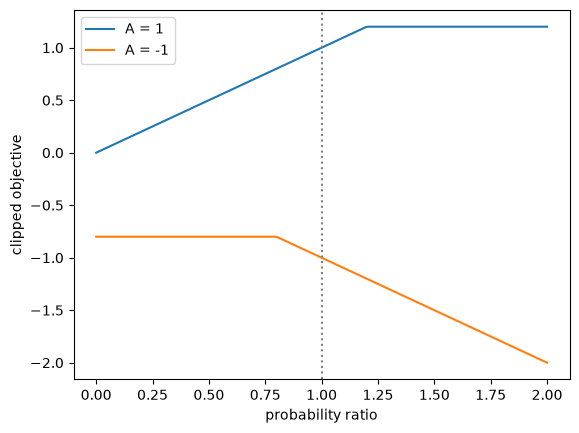

In [27]:
rho = np.linspace(0, 2, 200)
for A_ in [1, -1]:
  plt.plot(rho, np.minimum(rho * A_, np.clip(rho, 0.8, 1.2) * A_), label=f'A = {A_}')
plt.axvline(1, color='gray', ls=':'); plt.xlabel('probability ratio'); plt.ylabel('clipped objective'); plt.legend()

In [28]:
try:
  from stable_baselines3 import PPO
  from stable_baselines3.common.evaluation import evaluate_policy
  start = time.perf_counter()
  ppo = PPO('MlpPolicy', gym.make('CartPole-v1'), seed=0, verbose=0, device='cpu').learn(30_000)
  mean_reward, std_reward = evaluate_policy(ppo, gym.make('CartPole-v1'), n_eval_episodes=10)
  print({'mean reward': mean_reward, 'standard deviation': std_reward, 'time (s)': time.perf_counter() - start})
except ImportError:
  print('stable-baselines3 is not installed: run the installation cell of this part')

~\.venvs\apm50441\Lib\site-packages\stable_baselines3\common\evaluation.py:71: UserWarning: Evaluation environment is not wrapped with a ``Monitor`` wrapper. This may result in reporting modified episode lengths and rewards, if other wrappers happen to modify these. Consider wrapping environment first with ``Monitor`` wrapper.
  warnings.warn(


{'mean reward': np.float64(500.0), 'standard deviation': np.float64(0.0), 'time (s)': 56.01058829999238}


**Conclusion** The clipped objective is flat when the probability ratio leaves $[0.8, 1.2]$ in the direction favored by the advantage: for $A > 0$, increasing the probability beyond $1.2$ times the old one brings nothing; for $A < 0$, decreasing it below $0.8$ times brings nothing. Other samples can still move this ratio through shared parameters. Clipping gives no hard policy-distance guarantee. The PPO of `stable-baselines3` reaches the maximum return of $500$ on all the $10$ evaluation episodes after $30\,000$ steps, in about a minute: a well-tuned library implementation is more robust than our DQN.

---

### Preferences: reward model and DPO (★★)

RLHF learns from comparisons: a human prefers answer $y_1$ to $y_2$ with probability $\sigma(r(y_1) - r(y_2))$ (Bradley–Terry). The classical pipeline fits a reward model on the preferences, then maximizes $\mathbb{E}_\pi[r] - \beta\,\text{KL}(\pi\|\pi_{\text{ref}})$, whose solution is $\pi_\star \propto \pi_{\text{ref}}e^{r/\beta}$ (PC6). DPO (Rafailov et al., 2023) plugs this solution into the Bradley–Terry likelihood and fits the policy *directly* on the preferences: $-\log\sigma\big(\beta\log\frac{\pi(y_w)}{\pi_{\text{ref}}(y_w)} - \beta\log\frac{\pi(y_l)}{\pi_{\text{ref}}(y_l)}\big)$.

**Question** Take a single prompt with $20$ possible answers, true rewards $r \sim \mathcal{N}(0, 1)$, a uniform reference policy and $\beta = 0.5$. Simulate $2000$ preferences between random pairs of answers. Fit (i) a reward model by logistic regression on the pairs, then the KL-regularized policy; (ii) the DPO policy by gradient descent on its loss (logits of a softmax policy). Compare both with $\pi_\star$ (total variation distance) and their expected true rewards.

**Answer**

In [29]:
rng = np.random.default_rng(0)
n_answers, beta = 20, 0.5
r_true = rng.normal(size=n_answers)
pi_ref = np.full(n_answers, 1 / n_answers)
pi_star = pi_ref * np.exp(r_true / beta); pi_star /= pi_star.sum()
pairs = np.array([rng.choice(n_answers, 2, replace=False) for _ in range(2000)])
first_wins = rng.random(2000) < 1 / (1 + np.exp(-(r_true[pairs[:, 0]] - r_true[pairs[:, 1]])))
winners, losers = np.where(first_wins, pairs[:, 0], pairs[:, 1]), np.where(first_wins, pairs[:, 1], pairs[:, 0])
w_idx, l_idx = torch.tensor(winners), torch.tensor(losers)
reward_model = torch.zeros(n_answers, requires_grad=True)                     # (i) Bradley-Terry reward model
optimizer = torch.optim.Adam([reward_model], lr=0.05)
for _ in range(2000):
  loss = -torch.nn.functional.logsigmoid(reward_model[w_idx] - reward_model[l_idx]).mean()
  optimizer.zero_grad(); loss.backward(); optimizer.step()
r_hat = reward_model.detach().numpy()
pi_rlhf = pi_ref * np.exp(r_hat / beta); pi_rlhf /= pi_rlhf.sum()
logits = torch.zeros(n_answers, requires_grad=True)                           # (ii) DPO
log_ref = torch.log(torch.tensor(pi_ref, dtype=torch.float32))
optimizer = torch.optim.Adam([logits], lr=0.05)
for _ in range(2000):
  log_pi = torch.log_softmax(logits, dim=0)
  loss = -torch.nn.functional.logsigmoid(beta * ((log_pi - log_ref)[w_idx] - (log_pi - log_ref)[l_idx])).mean()
  optimizer.zero_grad(); loss.backward(); optimizer.step()
pi_dpo = torch.softmax(logits, dim=0).detach().numpy()
{name: {'TV distance to pi*': 0.5 * np.abs(p - pi_star).sum(), 'expected true reward': p @ r_true}
 for name, p in [('reference', pi_ref), ('reward model + KL', pi_rlhf), ('DPO', pi_dpo), ('pi*', pi_star)]}

{'reference': {'TV distance to pi*': np.float64(0.5372637720329586),
  'expected true reward': np.float64(-0.18317831742872687)},
 'reward model + KL': {'TV distance to pi*': np.float64(0.15151260716432297),
  'expected true reward': np.float64(0.8175157982464274)},
 'DPO': {'TV distance to pi*': np.float64(0.15150924627229828),
  'expected true reward': np.float64(0.8175107070941094)},
 'pi*': {'TV distance to pi*': np.float64(0.0),
  'expected true reward': np.float64(0.8112093920558582)}}

**Conclusion** The reference policy (uniform) has an expected true reward of $-0.18$; the KL-regularized optimum $\pi_\star \propto \pi_{\text{ref}}e^{r/\beta}$ reaches $0.81$. The two-step pipeline (Bradley–Terry reward model, then KL-regularized policy) and DPO give the same policy (total variation distance $0.15$ to $\pi_\star$ for both, the same expected reward $0.82$): DPO is the same estimator written directly in terms of the policy, without fitting a reward model nor running RL. The remaining distance to $\pi_\star$ comes from the finite number of preferences.

---

### A tiny agent with retrieval (★★★)

An *agent* is a language model in a loop: at each step it can call a tool (a search engine, a calculator...), read the result, and decide what to do next, until it answers (lecture: *The Agent Loop*). *Retrieval-augmented generation* (RAG) puts the documents retrieved for the question in the prompt. We use a small open model (Qwen2.5-0.5B-Instruct, about $1$ GB, downloaded once; a GPU runtime on Colab is faster, and a laptop CPU takes a few minutes) with two tools: a retriever over a few notes on this lab (BM25-like scores) and a calculator. Small models are unreliable agents: the point is to see the loop, and its failures.

**Question** Run the agent loop below on the three questions. For each step, look at the model's output, the tool call and the observation. Then estimate the cost of an agent: if each step reads a context of $3000$ tokens and writes $200$ tokens, with prices of $1\$$ per million input tokens and $4\$$ per million output tokens, how much does a $10$-step task cost? If each step succeeds independently with probability $0.95$, what is the probability that the $10$ steps all succeed?

**Answer**

In [30]:
import re
NOTES = ["Cliff Walking is a 4 x 12 grid; each step costs -1 and stepping into the cliff costs -100.",
         "The optimal path along the cliff has 13 steps; the safe path along the top has 17 steps.",
         "SARSA learns the safe path with epsilon-greedy exploration, Q-learning learns the optimal path.",
         "With a slip probability of 10%, dynamic programming with discount 0.9 chooses a path away from the cliff.",
         "REINFORCE with the reward-to-go has a smaller variance than with the full return.",
         "GRPO normalizes the rewards of a group of answers to the same prompt to compute the advantages."]
note_tokens = [set(re.findall(r'[a-z0-9]+', n.lower())) for n in NOTES]
def search(query):
  q = set(re.findall(r'[a-z0-9]+', query.lower()))
  scores = [len(q & t) / np.sqrt(len(t)) for t in note_tokens]
  return NOTES[int(np.argmax(scores))]
def calculator(expression):
  if not re.fullmatch(r'[0-9+\-*/(). ]+', expression):
    return 'error: only numbers and + - * / ( ) are allowed'
  return str(eval(expression))
SYSTEM = ("You answer questions about a reinforcement learning lab, using tools. Each of your messages is exactly one line, one of:\n"
          "SEARCH: <query>       (search the lab notes)\n"
          "CALC: <expression>    (compute with numbers and + - * / ( ))\n"
          "ANSWER: <answer>      (your final answer)\n"
          "Search the notes first. As soon as an observation gives what you need, compute if needed, then answer.")

In [31]:
try:
  import transformers
  transformers.logging.set_verbosity_error()
  generator = transformers.pipeline('text-generation', model='Qwen/Qwen2.5-0.5B-Instruct', device_map='auto')
  generator.model.generation_config.max_length = None
except Exception as error:                                            # no transformers, no network...
  generator = None
  print('The model could not be loaded:', error)
def agent(question, max_steps=5):
  messages = [{'role': 'system', 'content': SYSTEM}, {'role': 'user', 'content': question}]
  for step in range(max_steps):
    output = generator(messages, max_new_tokens=60, do_sample=False)[0]['generated_text'][-1]['content'].strip()
    print(f'  [model] {output}')
    messages.append({'role': 'assistant', 'content': output})
    if m := re.search(r'ANSWER:\s*(.*)', output):
      return m.group(1)
    if m := re.search(r'SEARCH:\s*(.*)', output):
      observation = search(m.group(1))
    elif m := re.search(r'CALC:\s*(.*)', output):
      observation = calculator(m.group(1).strip())
    else:
      observation = 'Please use SEARCH:, CALC: or ANSWER:.'
    print(f'  [tool]  {observation}')
    messages.append({'role': 'user', 'content': f'Observation: {observation}\nIf this is enough, reply with ANSWER: <answer> (or CALC: first if a computation is needed).'})
  return 'no answer'
if generator is not None:
  for question in ['How many steps has the safe path?', 'Which path does Q-learning learn?',
                   'How many more steps does the safe path take than the optimal path, in percent?']:
    print(question)
    print('  =>', agent(question))

~\.venvs\apm50441\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Loading weights:   4%|▍         | 12/290 [00:00<00:03, 84.88it/s]

Loading weights:   7%|▋         | 21/290 [00:00<00:04, 53.87it/s]

Loading weights:   9%|▉         | 27/290 [00:00<00:05, 50.60it/s]

Loading weights:  12%|█▏        | 35/290 [00:00<00:04, 55.85it/s]

... (12 outputs left out)

  [model] SARSA learns the safe path with epsilon-greedy exploration, while Q-learning learns the optimal path.
  [tool]  Please use SEARCH:, CALC: or ANSWER:.
  => no answer
How many more steps does the safe path take than the optimal path, in percent?


  [model] To calculate the difference between the number of steps taken by the safe path and the optimal path, we would typically need to know the specific problem or scenario being modeled. However, I can provide a general approach to solving this kind of problem.

Assuming that the safe path and the optimal path are defined
  [tool]  Please use SEARCH:, CALC: or ANSWER:.


  [model] SEARCH: How do I calculate the difference between the number of steps taken by the safe path and the optimal path?
  [tool]  The optimal path along the cliff has 13 steps; the safe path along the top has 17 steps.


  [model] ANSWER: The safe path takes 4 more steps than the optimal path.
  => The safe path takes 4 more steps than the optimal path.


In [32]:
cost_per_step = 3000 * 1 / 1e6 + 200 * 4 / 1e6
{'cost of a 10-step task ($)': 10 * cost_per_step, 'probability that 10 steps succeed': 0.95 ** 10}

{'cost of a 10-step task ($)': 0.038,
 'probability that 10 steps succeed': 0.5987369392383787}

**Conclusion** The small model follows the protocol only partly: it searches the notes and finds the right document, but it answers $20$ steps instead of the $17$ written in the observation, it paraphrases the observation instead of answering for the second question until it runs out of steps, and for the third it never uses the calculator: it answers without computing ($4$ more steps instead of a percentage) or computes in its head and gets it wrong ($28.6\%$ instead of $(17-13)/13 \approx 30.8\%$), depending on the machine (the generated text changes with the hardware and the library versions, even without sampling). Larger models are much more reliable agents, but the loop is the same. The cost estimate is $0.038$\$ per $10$-step task, and with $95\%$ of success per step, all the $10$ steps succeed with probability only $0.95^{10} \approx 0.60$: errors compound along an agent's trajectory, which is why agents need verification steps.

---

## About this lab

**Use of AI.** Artificial intelligence tools have been used to revise the content of this lab. The main contributor takes full responsibility for this content.

**License.** The texts of this lab are under the [Creative Commons Attribution-ShareAlike 4.0](https://creativecommons.org/licenses/by-sa/4.0/) license (CC BY-SA 4.0), and its code under the [MIT](https://opensource.org/license/mit) license; the datasets keep their own licenses. Main contributor: E. Le Pennec. Contributors: S. Boucheron, A. Dieuleveut, A.K. Fermin, S. Gadat, S. Gaiffas, B. Goujaud, A. Guilloux, Ch. Keribin, Th. Klein, E. Matzner, J. Read, M. Sangnier, E. Scornet.